# Capsule Endoscopy Perception — E0, E1, E2 and E3

This Google Colab notebook runs the complete experiment sequence and stores **datasets generated by this notebook, trained weights, training logs, plots, test metrics, and prediction images in Google Drive**.

## Experiments
- **E0:** Baseline YOLOv8n on the original images.
- **E1:** Sakaguchi-type directional image enhancement → YOLOv8n.
- **E2:** E1 + Grünwald–Letnikov fractional-derivative enhancement (α = 0.5) → YOLOv8n.
- **E3:** E2 + 2D Discrete Wavelet Transform detail enhancement → YOLOv8n.

Each model starts from `yolov8n.pt` pretrained weights and is trained independently with the same data split and training settings. This isolates the effect of the image preprocessing pipeline.

**Important:** E1's four-direction averaging and E2's weighted blend are project implementation choices. E3 is an experimental design to evaluate, not a guaranteed improvement. All reported performance must come from the runs completed in this notebook.

**Before running:** In Colab, select **Runtime → Change runtime type → T4 GPU** (or another supported GPU). Run cells in order. The original dataset is read-only; generated experiment files are written to a new timestamped folder in Drive. Re-running the setup cell creates a new experiment folder rather than overwriting this run.
**Recovery note:** the E1 preprocessing cell rebuilds an incomplete `E1_Sakaguchi` generated dataset from the verified source split. The notebook no longer includes the temporary troubleshooting cells that copied unenhanced source images into E1. E0 artifacts are not removed.


## Professor's fresh-run setup
Before running all cells, ensure Google Drive contains:
- `My Drive/Capsule_Perception/Kvasir-SEG.yolov8_split/` with `train`, `valid`, and `test` image/label folders.
- The two source videos inside `My Drive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/Videos/`:
  - `512722d1-05f9-4454-a343-7aba1fb462c2.avi`
  - `df1aa095-0cab-4433-97fe-00d456f33615.avi`

The notebook generates the E4 HMM configuration and implementation during execution. It must be run from top to bottom in a fresh Colab runtime. If you need to repeat the entire run later, change `Professor_Fresh_Run` consistently in the setup and hardcoded paths to a new folder name before executing.


## 1. Install dependencies and mount Google Drive

In [ ]:
%pip -q install ultralytics==8.4.152 opencv-python-headless PyWavelets scipy pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 10.9 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/Capsule_Perception')

# This is a NEW output folder for the professor's run.
# Keep the dataset at PROJECT_DIR / 'Kvasir-SEG.yolov8_split'.
# Before running, copy the two E4 source videos into:
# PROJECT_DIR / 'experiments' / 'Professor_Fresh_Run' / 'E4_Final_HMM' / 'Videos'
EXPERIMENT_DIR = PROJECT_DIR / 'experiments' / 'Professor_Fresh_Run'

SOURCE_DATASET = PROJECT_DIR / 'Kvasir-SEG.yolov8_split'

DATASETS_DIR = EXPERIMENT_DIR / 'datasets'
CONFIGS_DIR = EXPERIMENT_DIR / 'configs'
TRAIN_RUNS_DIR = EXPERIMENT_DIR / 'training_runs'
EVALUATION_DIR = EXPERIMENT_DIR / 'evaluations'
PREDICTIONS_DIR = EXPERIMENT_DIR / 'predictions'

# Create fresh output directories. Do not delete or overwrite your original run.
for folder in [
    EXPERIMENT_DIR,
    DATASETS_DIR,
    CONFIGS_DIR,
    TRAIN_RUNS_DIR,
    EVALUATION_DIR,
    PREDICTIONS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

assert SOURCE_DATASET.exists(), (
    f"Source dataset not found: {SOURCE_DATASET}. "
    "Upload/copy Kvasir-SEG.yolov8_split into My Drive/Capsule_Perception first."
)

print("Fresh experiment output directory:")
print(EXPERIMENT_DIR)
print("\nSource dataset:")
print(SOURCE_DATASET)
print("\nExisting project results are not being used as training outputs.")


Mounted at /content/drive
Fresh experiment output directory:
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run

Source dataset:
/content/drive/MyDrive/Capsule_Perception/Kvasir-SEG.yolov8_split

Existing project results are not being used as training outputs.


## 2. Verify the source dataset and freeze the split

In [ ]:
import json

assert SOURCE_DATASET.exists(), f'Dataset not found: {SOURCE_DATASET}'

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
SPLITS = ['train', 'valid', 'test']
EXPECTED_COUNTS = {'train': 700, 'valid': 150, 'test': 150}


def image_files(folder):
    return sorted([p for p in folder.iterdir()
                   if p.is_file() and p.suffix.lower() in IMAGE_EXTS])


def validate_split(dataset_dir, expected_counts=None):
    summary = {}
    for split in SPLITS:
        images_dir = dataset_dir / split / 'images'
        labels_dir = dataset_dir / split / 'labels'
        assert images_dir.exists(), f'Missing {images_dir}'
        assert labels_dir.exists(), f'Missing {labels_dir}'
        images = image_files(images_dir)
        labels = sorted(labels_dir.glob('*.txt'))
        image_stems = {p.stem for p in images}
        label_stems = {p.stem for p in labels}
        missing_labels = sorted(image_stems - label_stems)
        extra_labels = sorted(label_stems - image_stems)
        assert not missing_labels, f'{split}: images missing labels: {missing_labels[:5]}'
        assert not extra_labels, f'{split}: labels without images: {extra_labels[:5]}'
        if expected_counts:
            assert len(images) == expected_counts[split], (
                f'{split}: expected {expected_counts[split]} images, got {len(images)}')
        summary[split] = {'images': len(images), 'labels': len(labels)}
    return summary

source_summary = validate_split(SOURCE_DATASET, EXPECTED_COUNTS)
print(json.dumps(source_summary, indent=2))

# Store a record of the source split in the experiment folder.
with open(EXPERIMENT_DIR / 'source_dataset_split.json', 'w') as f:
    json.dump({'source_dataset': str(SOURCE_DATASET),
               'counts': source_summary,
               'note': 'Original dataset is read-only; labels and split assignments are preserved.'}, f, indent=2)

{
  "train": {
    "images": 700,
    "labels": 700
  },
  "valid": {
    "images": 150,
    "labels": 150
  },
  "test": {
    "images": 150,
    "labels": 150
  }
}


In [ ]:
import yaml
# Create an experiment-specific data.yaml using absolute paths.
# This avoids ambiguity about how relative paths are resolved.
def write_data_yaml(dataset_dir, config_path):
    config = {
        'path': str(dataset_dir),
        'train': str(dataset_dir / 'train' / 'images'),
        'val': str(dataset_dir / 'valid' / 'images'),
        'test': str(dataset_dir / 'test' / 'images'),
        'nc': 1,
        'names': ['Polyp']
    }
    with open(config_path, 'w') as f:
        yaml.safe_dump(config, f, sort_keys=False)
    return config_path

E0_CONFIG = write_data_yaml(SOURCE_DATASET, CONFIGS_DIR / 'E0_data.yaml')
print(E0_CONFIG.read_text())

path: /content/drive/MyDrive/Capsule_Perception/Kvasir-SEG.yolov8_split
train: /content/drive/MyDrive/Capsule_Perception/Kvasir-SEG.yolov8_split/train/images
val: /content/drive/MyDrive/Capsule_Perception/Kvasir-SEG.yolov8_split/valid/images
test: /content/drive/MyDrive/Capsule_Perception/Kvasir-SEG.yolov8_split/test/images
nc: 1
names:
- Polyp



## 3. Shared training and evaluation helpers

In [ ]:
from ultralytics import YOLO
import json
import csv

EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 16
RANDOM_SEED = 42
WORKERS = 2
DEVICE = 0  # Colab GPU; set to 'cpu' only if no GPU is available.

metrics_summary = []


def train_experiment(tag, data_yaml):
    """Train a fresh YOLOv8n model and save all training artifacts in Drive."""
    run_dir = TRAIN_RUNS_DIR / tag
    assert not run_dir.exists(), f'{run_dir} already exists; use a new experiment folder.'
    model = YOLO('yolov8n.pt')
    model.train(
        data=str(data_yaml),
        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        workers=WORKERS,
        seed=RANDOM_SEED,
        deterministic=True,
        project=str(TRAIN_RUNS_DIR),
        name=tag,
        exist_ok=False,
        pretrained=True,
        patience=20,
        plots=True,
        save=True,
        verbose=True
    )
    best_path = run_dir / 'weights' / 'best.pt'
    last_path = run_dir / 'weights' / 'last.pt'
    assert best_path.exists(), f'Best weights not found: {best_path}'
    assert last_path.exists(), f'Last weights not found: {last_path}'
    print('Best weights:', best_path)
    print('Last weights:', last_path)
    return best_path


def evaluate_experiment(tag, best_path, data_yaml):
    """Evaluate once on the held-out test split and persist metrics/plots."""
    eval_dir = EVALUATION_DIR / tag
    eval_dir.mkdir(parents=True, exist_ok=True)
    model = YOLO(str(best_path))
    result = model.val(
        data=str(data_yaml),
        split='test',
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        plots=True,
        project=str(eval_dir),
        name='test',
        exist_ok=True,
        verbose=True
    )
    row = {
        'experiment': tag,
        'precision': float(result.box.mp),
        'recall': float(result.box.mr),
        'mAP50': float(result.box.map50),
        'mAP50_95': float(result.box.map),
        'best_weights': str(best_path),
        'data_yaml': str(data_yaml),
        'test_images': source_summary['test']['images'],
        'test_labels': source_summary['test']['labels']
    }
    metrics_summary.append(row)
    with open(eval_dir / 'test_metrics.json', 'w') as f:
        json.dump(row, f, indent=2)
    save_metrics_table()
    print(json.dumps(row, indent=2))
    return row


def save_metrics_table():
    output_csv = EXPERIMENT_DIR / 'model_comparison.csv'
    if metrics_summary:
        with open(output_csv, 'w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=list(metrics_summary[0].keys()))
            writer.writeheader()
            writer.writerows(metrics_summary)
    print('Comparison CSV:', output_csv)


def save_test_predictions(tag, best_path, data_yaml, dataset_dir):
    """Save prediction images from the matching experiment's test images to Drive."""
    model = YOLO(str(best_path))
    out_dir = PREDICTIONS_DIR / tag
    out_dir.mkdir(parents=True, exist_ok=True)
    test_images_dir = dataset_dir / 'test' / 'images'
    model.predict(
        source=str(test_images_dir),
        data=str(data_yaml),
        imgsz=IMAGE_SIZE,
        conf=0.5,
        device=DEVICE,
        save=True,
        save_conf=True,
        project=str(out_dir),
        name='test_predictions',
        exist_ok=True,
        verbose=False
    )
    print('Prediction images saved under:', out_dir / 'test_predictions')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## 4. E0 — Baseline YOLOv8n on original images

E0 uses the original images with no custom enhancement. This notebook trains E0 to gather artifacts from the start. If your selected experiment folder already contains `training_runs/E0_baseline` or its evaluation/prediction outputs, do not rerun the E0 training/evaluation cells into that same folder; continue from the saved `best.pt` and proceed to E1. The original source dataset is not changed.


In [ ]:
E0_BEST = train_experiment('E0_baseline', E0_CONFIG)

New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/configs/E0_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.0

In [ ]:
E0_METRICS = evaluate_experiment('E0_baseline', E0_BEST, E0_CONFIG)
save_test_predictions('E0_baseline', E0_BEST, E0_CONFIG, SOURCE_DATASET)

Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.7±0.4 ms, read: 95.0±132.0 MB/s, size: 346.9 KB)
val: Scanning /content/drive/MyDrive/Capsule_Perception/Kvasir-SEG.yolov8_split/test/labels... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 1.9it/s 1:19
val: New cache created: /content/drive/MyDrive/Capsule_Perception/Kvasir-SEG.yolov8_split/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.2it/s 4.5s
                   all        150        156      0.895      0.936      0.938      0.742
Speed: 3.9ms preprocess, 6.3ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/evaluations/E0_baseline/test
Comparison CSV: /content/drive/MyDrive/Capsule_Percepti

## 5. E1 — Sakaguchi-type directional enhancement

The E1 builder applies the four directional masks, averages the responses, normalizes the result, and replicates it into three channels for YOLOv8n. It preserves the original train/validation/test membership and labels. If an incomplete E1 dataset already exists, the E1 builder will rebuild only that generated dataset from the verified source; it will not delete E0 weights or evaluations.


In [ ]:
from scipy.special import gamma
import numpy as np
import shutil
import cv2
import yaml
import json

THETA = 0.1
EPSILON = 0.01
summation = 0.0
for k in range(2, 1000):
    term = (EPSILON ** k) / gamma(THETA + k)
    summation += term
    if abs(term) < 1e-20:
        break

o1 = 1.0
o2 = gamma(1 + THETA) * summation / 75.005
o3 = gamma(2 + THETA) * summation / 1.125075

M0 = np.array([[0, 0, 0], [o1, o2, o3], [0, 0, 0]], dtype=np.float32)
M90 = np.array([[0, o3, 0], [0, o2, 0], [0, o1, 0]], dtype=np.float32)
M45 = np.array([[0, 0, o3], [0, o2, 0], [o1, 0, 0]], dtype=np.float32)
M135 = np.array([[o3, 0, 0], [0, o2, 0], [0, 0, o1]], dtype=np.float32)

print({'theta': THETA, 'o1': float(o1), 'o2': float(o2), 'o3': float(o3), 'series_terms': k})


def sakaguchi_enhancement(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    # Use float responses to avoid uint8 overflow/clipping during convolution.
    gray_f = gray.astype(np.float32)
    responses = [cv2.filter2D(gray_f, cv2.CV_32F, mask)
                 for mask in [M0, M90, M45, M135]]
    enhanced = np.mean(responses, axis=0)
    # Normalize to an 8-bit image for stable storage and visualization.
    enhanced = cv2.normalize(enhanced, None, 0, 255, cv2.NORM_MINMAX)
    enhanced = np.clip(enhanced, 0, 255).astype(np.uint8)
    return cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR)


def build_enhanced_dataset(source_dir, output_dir, transform, description):
    """Build a new image dataset while preserving all split names and labels."""
    if output_dir.exists():
        if output_dir.name == 'E1_Sakaguchi':
            # E1 may be left incomplete by an interrupted earlier run.
            # Rebuild only this generated dataset from SOURCE_DATASET.
            print(f'Rebuilding existing E1 dataset only: {output_dir}')
            shutil.rmtree(output_dir)
        else:
            raise FileExistsError(
                f'Output dataset already exists: {output_dir}. '
                'Keeping existing E2/E3 datasets safe; inspect or rename the folder before rerunning.'
            )
    output_dir.mkdir(parents=True)
    for split in SPLITS:
        src_images = source_dir / split / 'images'
        src_labels = source_dir / split / 'labels'
        dst_images = output_dir / split / 'images'
        dst_labels = output_dir / split / 'labels'
        dst_images.mkdir(parents=True)
        dst_labels.mkdir(parents=True)
        files = image_files(src_images)
        for idx, image_path in enumerate(files, start=1):
            image = cv2.imread(str(image_path))
            if image is None:
                raise ValueError(f'Could not read image: {image_path}')
            processed = transform(image)
            if not cv2.imwrite(str(dst_images / image_path.name), processed):
                raise IOError(f'Could not save image: {image_path.name}')
            label_path = src_labels / f'{image_path.stem}.txt'
            if not label_path.exists():
                raise FileNotFoundError(f'Missing label: {label_path}')
            shutil.copy2(label_path, dst_labels / label_path.name)
            if idx % 100 == 0 or idx == len(files):
                print(f'{split}: {idx}/{len(files)}')
    write_data_yaml(output_dir, CONFIGS_DIR / f'{output_dir.name}_data.yaml')
    counts = validate_split(output_dir, EXPECTED_COUNTS)
    with open(output_dir / 'preprocessing_info.json', 'w') as f:
        json.dump({'description': description, 'counts': counts,
                   'labels_and_split_membership_preserved': True}, f, indent=2)
    return CONFIGS_DIR / f'{output_dir.name}_data.yaml'

E1_DATASET = DATASETS_DIR / 'E1_Sakaguchi'
E1_CONFIG = build_enhanced_dataset(
    SOURCE_DATASET, E1_DATASET, sakaguchi_enhancement,
    'Grayscale Sakaguchi-type four-direction mask responses averaged and replicated to three channels.'
)
print('E1 dataset:', E1_DATASET)
print('E1 config:', E1_CONFIG)

{'theta': 0.1, 'o1': 1.0, 'o2': 1.2178306940560365e-06, 'o3': 8.9307584230776e-05, 'series_terms': 9}
train: 100/700
train: 200/700
train: 300/700
train: 400/700
train: 500/700
train: 600/700
train: 700/700
valid: 100/150
valid: 150/150
test: 100/150
test: 150/150
E1 dataset: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E1_Sakaguchi
E1 config: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/configs/E1_Sakaguchi_data.yaml


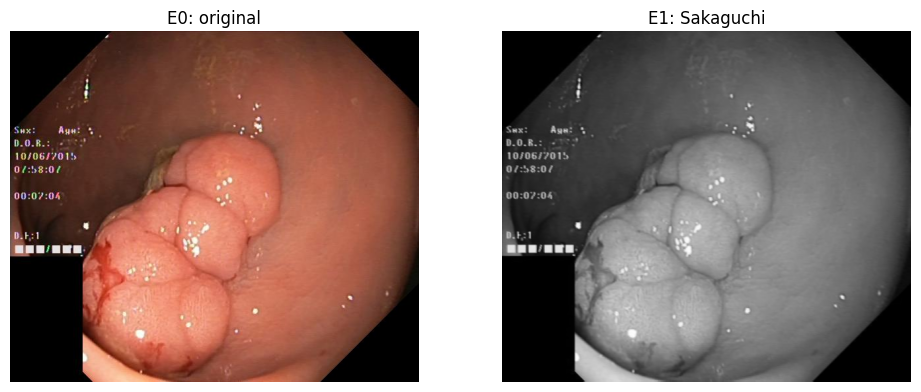

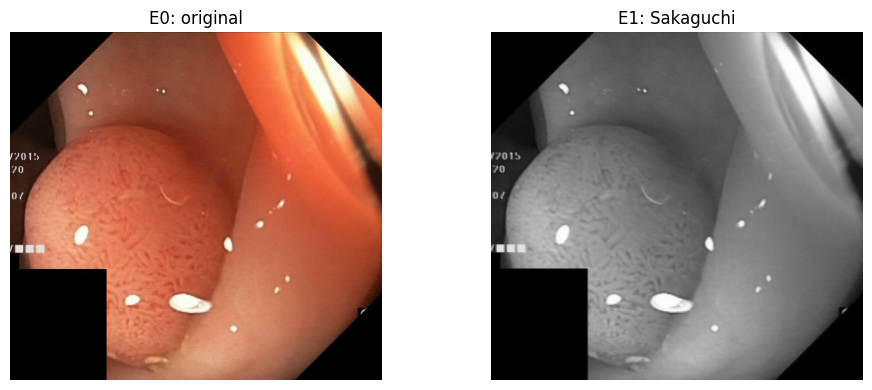

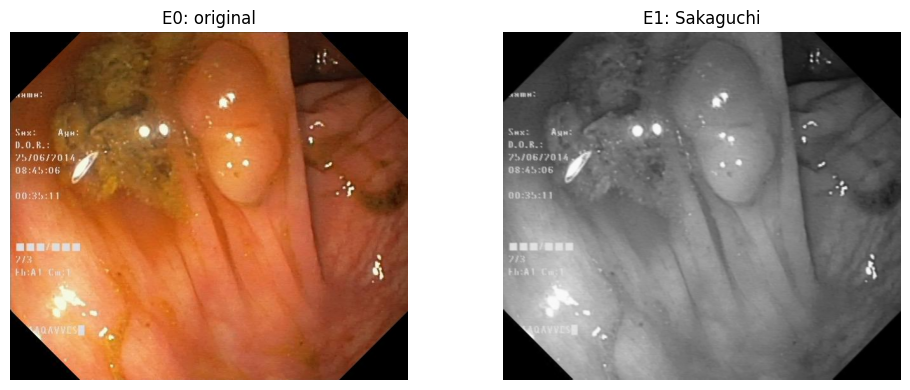

In [ ]:
# Visual sanity check: original versus E1.
import random
import matplotlib.pyplot as plt

samples = random.Random(42).sample(image_files(SOURCE_DATASET / 'train' / 'images'), min(3, len(image_files(SOURCE_DATASET / 'train' / 'images'))))
for p in samples:
    original = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    enhanced = cv2.cvtColor(cv2.imread(str(E1_DATASET / 'train' / 'images' / p.name)), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(original); ax[0].set_title('E0: original'); ax[0].axis('off')
    ax[1].imshow(enhanced); ax[1].set_title('E1: Sakaguchi'); ax[1].axis('off')
    plt.tight_layout(); plt.show()

In [ ]:
E1_BEST = train_experiment('E1_Sakaguchi', E1_CONFIG)

New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/configs/E1_Sakaguchi_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0

In [ ]:
import csv

E1_METRICS = evaluate_experiment('E1_Sakaguchi', E1_BEST, E1_CONFIG)
save_test_predictions('E1_Sakaguchi', E1_BEST, E1_CONFIG, E1_DATASET)

Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 2.2±2.8 ms, read: 87.1±59.5 MB/s, size: 265.9 KB)
val: Scanning /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E1_Sakaguchi/test/labels... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 235.6it/s 0.6s
val: New cache created: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E1_Sakaguchi/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.7it/s 3.8s
                   all        150        156      0.899      0.855      0.922      0.719
Speed: 3.8ms preprocess, 4.9ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/evaluations/E1_Sakaguch

## 6. E2 — E1 + Grünwald–Letnikov fractional derivative

E2 starts from the E1 enhanced images. It computes a truncated Grünwald–Letnikov-inspired derivative with α = 0.5 along horizontal and vertical axes, normalizes the derivative magnitude, and blends it with the E1 grayscale image using a 0.2 detail weight. This is the project's discrete implementation, not a claim that this exact blend is mandated by a particular paper.

In [ ]:
ALPHA = 0.5
BLEND = 0.2

def fractional_gl_enhancement(img, alpha=ALPHA, blend=BLEND):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img.copy()
    gray = gray.astype(np.float32)

    # Three-term truncated GL response, with reflected padding at the borders.
    padded_x = np.pad(gray, ((0, 0), (2, 0)), mode='reflect')
    f0_x, f1_x, f2_x = padded_x[:, 2:], padded_x[:, 1:-1], padded_x[:, :-2]
    dx = f0_x - alpha * f1_x + (alpha * (alpha - 1) / 2.0) * f2_x

    padded_y = np.pad(gray, ((2, 0), (0, 0)), mode='reflect')
    f0_y, f1_y, f2_y = padded_y[2:, :], padded_y[1:-1, :], padded_y[:-2, :]
    dy = f0_y - alpha * f1_y + (alpha * (alpha - 1) / 2.0) * f2_y

    magnitude = np.sqrt(dx ** 2 + dy ** 2)
    derivative_norm = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.float32)
    enhanced = (1.0 - blend) * gray + blend * derivative_norm
    enhanced = np.clip(enhanced, 0, 255).astype(np.uint8)
    return cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR)

E2_DATASET = DATASETS_DIR / 'E2_Sakaguchi_Fractional'
E2_CONFIG = build_enhanced_dataset(
    E1_DATASET, E2_DATASET,
    lambda image: fractional_gl_enhancement(image, alpha=ALPHA, blend=BLEND),
    f'E1 images enhanced with truncated GL derivative alpha={ALPHA}, blend={BLEND}.'
)
print('E2 dataset:', E2_DATASET)
print('E2 config:', E2_CONFIG)

train: 100/700
train: 200/700
train: 300/700
train: 400/700
train: 500/700
train: 600/700
train: 700/700
valid: 100/150
valid: 150/150
test: 100/150
test: 150/150
E2 dataset: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E2_Sakaguchi_Fractional
E2 config: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/configs/E2_Sakaguchi_Fractional_data.yaml


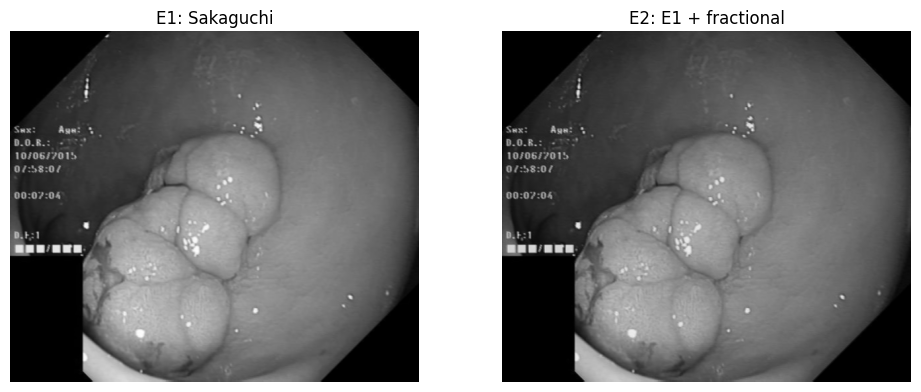

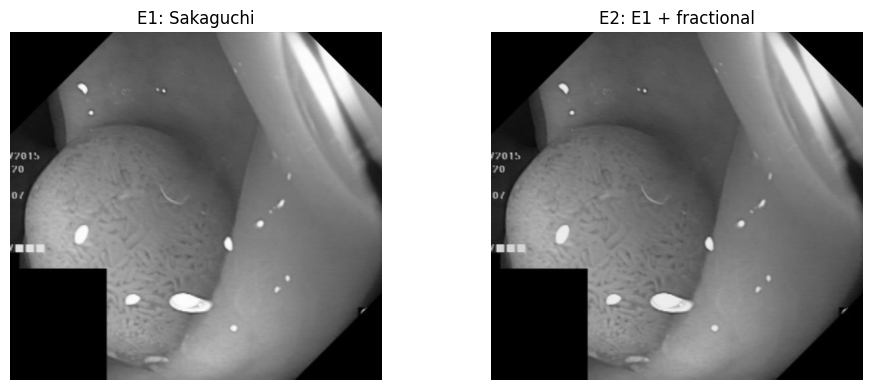

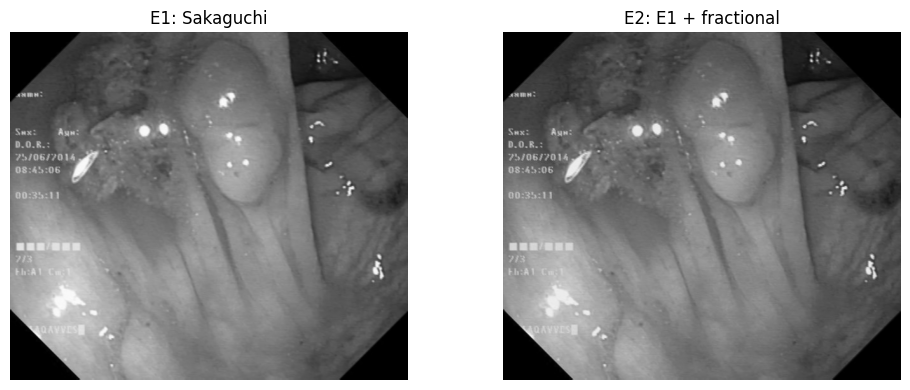

In [ ]:
# Visual sanity check: E1 versus E2.
samples = random.Random(42).sample(image_files(E1_DATASET / 'train' / 'images'), 3)
for p in samples:
    e1 = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    e2 = cv2.cvtColor(cv2.imread(str(E2_DATASET / 'train' / 'images' / p.name)), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(e1); ax[0].set_title('E1: Sakaguchi'); ax[0].axis('off')
    ax[1].imshow(e2); ax[1].set_title('E2: E1 + fractional'); ax[1].axis('off')
    plt.tight_layout(); plt.show()

In [ ]:
E2_BEST = train_experiment('E2_Sakaguchi_Fractional', E2_CONFIG)

New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/configs/E2_Sakaguchi_Fractional_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=No

In [ ]:
E2_METRICS = evaluate_experiment('E2_Sakaguchi_Fractional', E2_BEST, E2_CONFIG)
save_test_predictions('E2_Sakaguchi_Fractional', E2_BEST, E2_CONFIG, E2_DATASET)

Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 11.5±24.0 ms, read: 84.6±66.5 MB/s, size: 281.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E2_Sakaguchi_Fractional/test/labels... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 236.4it/s 0.6s
val: New cache created: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E2_Sakaguchi_Fractional/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.5it/s 3.9s
                   all        150        156      0.895       0.84      0.911       0.72
Speed: 4.4ms prep

## 7. E3 — E2 + 2D Discrete Wavelet Transform (DWT) detail enhancement

E3 is an exploratory next step. A 2D DWT decomposes the E2 image into approximation (LL) and detail (LH, HL, HH) subbands. The implementation leaves LL unchanged and multiplies detail coefficients by a modest factor (1.2), then reconstructs the image using inverse DWT. The factor is a project hyperparameter to evaluate, not a guaranteed optimal value.

In [ ]:
import pywt

WAVELET = 'haar'
DETAIL_GAIN = 1.2

def dwt_detail_enhancement(img, wavelet=WAVELET, detail_gain=DETAIL_GAIN):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img.copy()
    gray_f = gray.astype(np.float32)
    coeffs = pywt.dwt2(gray_f, wavelet, mode='symmetric')
    LL, (LH, HL, HH) = coeffs
    enhanced_coeffs = (
        LL,
        (LH * detail_gain, HL * detail_gain, HH * detail_gain)
    )
    reconstructed = pywt.idwt2(enhanced_coeffs, wavelet, mode='symmetric')
    reconstructed = reconstructed[:gray.shape[0], :gray.shape[1]]
    reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)
    return cv2.cvtColor(reconstructed, cv2.COLOR_GRAY2BGR)

E3_DATASET = DATASETS_DIR / 'E3_Sakaguchi_Fractional_DWT'
E3_CONFIG = build_enhanced_dataset(
    E2_DATASET, E3_DATASET,
    lambda image: dwt_detail_enhancement(image, wavelet=WAVELET, detail_gain=DETAIL_GAIN),
    f'E2 images processed using {WAVELET} 2D DWT; detail coefficients multiplied by {DETAIL_GAIN}.'
)
print('E3 dataset:', E3_DATASET)
print('E3 config:', E3_CONFIG)

train: 100/700
train: 200/700
train: 300/700
train: 400/700
train: 500/700
train: 600/700
train: 700/700
valid: 100/150
valid: 150/150
test: 100/150
test: 150/150
E3 dataset: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E3_Sakaguchi_Fractional_DWT
E3 config: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/configs/E3_Sakaguchi_Fractional_DWT_data.yaml


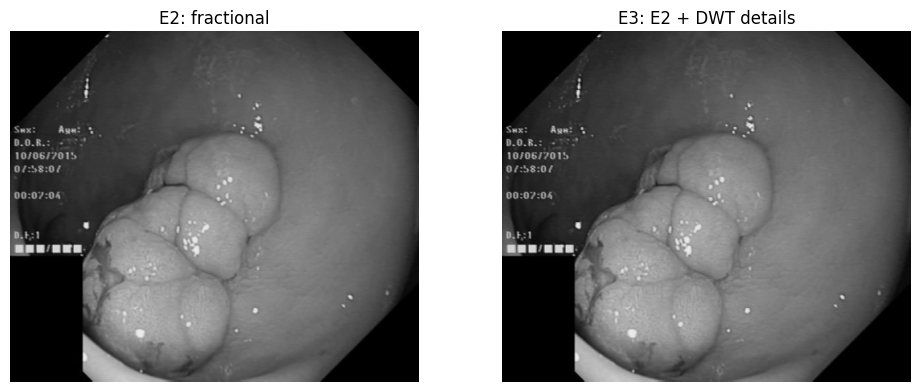

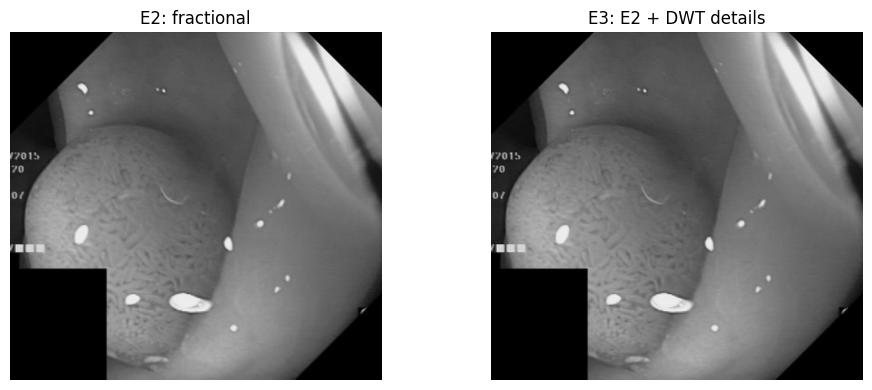

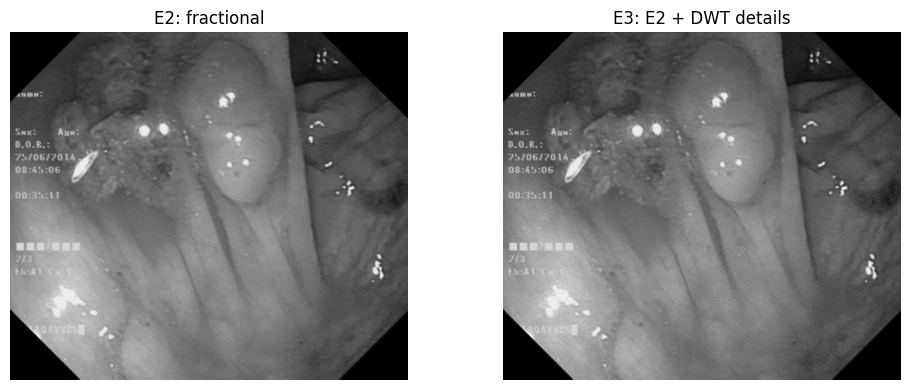

In [ ]:
# Visual sanity check: E2 versus E3.
samples = random.Random(42).sample(image_files(E2_DATASET / 'train' / 'images'), 3)
for p in samples:
    e2 = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    e3 = cv2.cvtColor(cv2.imread(str(E3_DATASET / 'train' / 'images' / p.name)), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(e2); ax[0].set_title('E2: fractional'); ax[0].axis('off')
    ax[1].imshow(e3); ax[1].set_title('E3: E2 + DWT details'); ax[1].axis('off')
    plt.tight_layout(); plt.show()

In [ ]:
E3_BEST = train_experiment('E3_Sakaguchi_Fractional_DWT', E3_CONFIG)

New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/configs/E3_Sakaguchi_Fractional_DWT_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_widt

In [ ]:
E3_METRICS = evaluate_experiment('E3_Sakaguchi_Fractional_DWT', E3_BEST, E3_CONFIG)
save_test_predictions('E3_Sakaguchi_Fractional_DWT', E3_BEST, E3_CONFIG, E3_DATASET)

Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.2 ms, read: 171.8±43.4 MB/s, size: 321.5 KB)
val: Scanning /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E3_Sakaguchi_Fractional_DWT/test/labels... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 221.3it/s 0.7s
val: New cache created: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E3_Sakaguchi_Fractional_DWT/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.5it/s 4.0s
                   all        150        156      0.905      0.914      0.936      0.723
Speed: 5.3ms preprocess, 5.6ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fr

## 8. Compare the completed experiments

,experiment,precision,recall,mAP50,mAP50_95
0,E0_baseline,0.894933,0.935897,0.937583,0.741682
1,E1_Sakaguchi,0.898897,0.854909,0.921805,0.719137
2,E2_Sakaguchi_Fractional,0.895166,0.839744,0.910975,0.719745
3,E3_Sakaguchi_Fractional_DWT,0.904820,0.914089,0.935582,0.722643


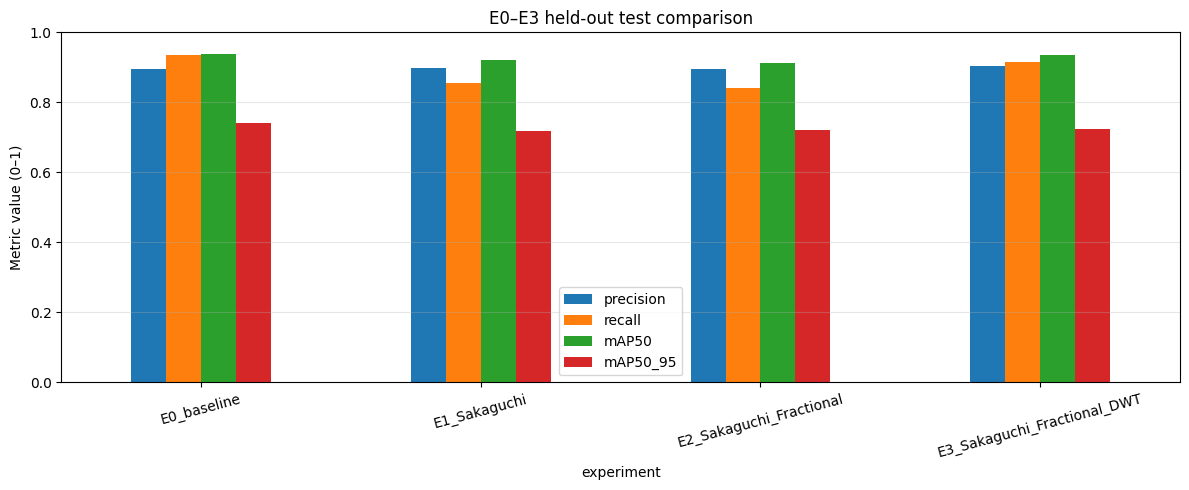


All completed outputs are in:
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run

Comparison CSV: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/model_comparison.csv
Comparison chart: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/model_comparison.png


In [ ]:
import pandas as pd
import json

RUN_ID = EXPERIMENT_DIR.name
comparison = pd.DataFrame(metrics_summary)
comparison_path = EXPERIMENT_DIR / 'model_comparison.csv'
comparison.to_csv(comparison_path, index=False)
display(comparison[['experiment', 'precision', 'recall', 'mAP50', 'mAP50_95']])

# A compact bar chart for the four models.
metric_cols = ['precision', 'recall', 'mAP50', 'mAP50_95']
plot_df = comparison.set_index('experiment')[metric_cols]
ax = plot_df.plot(kind='bar', figsize=(12, 5), ylim=(0, 1), rot=15)
ax.set_ylabel('Metric value (0–1)')
ax.set_title('E0–E3 held-out test comparison')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
chart_path = EXPERIMENT_DIR / 'model_comparison.png'
plt.savefig(chart_path, dpi=160, bbox_inches='tight')
plt.show()

with open(EXPERIMENT_DIR / 'experiment_manifest.json', 'w') as f:
    json.dump({
        'run_id': RUN_ID,
        'source_dataset': str(SOURCE_DATASET),
        'experiment_dir': str(EXPERIMENT_DIR),
        'training': {'epochs': EPOCHS, 'imgsz': IMAGE_SIZE,
                     'batch': BATCH_SIZE, 'seed': RANDOM_SEED,
                     'model': 'YOLOv8n', 'device': str(DEVICE)},
        'experiments': [
            {'name': 'E0', 'description': 'Baseline on original images'},
            {'name': 'E1', 'description': 'Sakaguchi-type directional enhancement'},
            {'name': 'E2', 'description': 'E1 + GL fractional derivative, alpha=0.5, blend=0.2'},
            {'name': 'E3', 'description': f'E2 + {WAVELET} DWT detail gain={DETAIL_GAIN}'}
        ],
        'metrics': metrics_summary
    }, f, indent=2)

print('\nAll completed outputs are in:')
print(EXPERIMENT_DIR)
print('\nComparison CSV:', comparison_path)
print('Comparison chart:', chart_path)

In [ ]:
from pathlib import Path

print("Experiment:", EXPERIMENT_DIR)

print("\nTraining CSV files:")
for file in sorted(EXPERIMENT_DIR.rglob("results.csv")):
    print(file)

print("\nComparison and evaluation CSV files:")
for file in sorted(EXPERIMENT_DIR.rglob("*.csv")):
    if file.name != "results.csv":
        print(file)

Experiment: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run

Training CSV files:
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E0_baseline/results.csv
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E1_Sakaguchi/results.csv
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E2_Sakaguchi_Fractional/results.csv
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E3_Sakaguchi_Fractional_DWT/results.csv

Comparison and evaluation CSV files:
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/model_comparison.csv


In [ ]:
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments"
)

for folder in ROOT.iterdir():
    if not folder.is_dir():
        continue

    print(f"\n📁 {folder.name}")

    for f in folder.rglob("*"):
        if f.is_file() and (
            f.suffix.lower() == ".csv"
            or "e0" in f.name.lower()
            or "baseline" in f.name.lower()
        ):
            print("  ", f.relative_to(folder))


📁 Professor_Fresh_Run
   model_comparison.csv
   configs/E0_data.yaml
   predictions/E3_Sakaguchi_Fractional_DWT/test_predictions/cju2yg5ht8i4p087800js8hp4_png.rf.nGAqL4KIrmick4I6Ie0c.jpg
   predictions/E3_Sakaguchi_Fractional_DWT/test_predictions/cju324q101fhe08350wae9cif_png.rf.KfbIRUIZn0rRS4ff8LuF.jpg
   predictions/E3_Sakaguchi_Fractional_DWT/test_predictions/cju5uxjnol2r509871qv2yeia_png.rf.6DsABp0dOQA1lV1Ee0HY.jpg
   predictions/E3_Sakaguchi_Fractional_DWT/test_predictions/cju892fesoq2g0801n0e0jyia_png.rf.nwLGktiUBMQTOyZdMJnj.jpg
   predictions/E2_Sakaguchi_Fractional/test_predictions/cju2yg5ht8i4p087800js8hp4_png.rf.nGAqL4KIrmick4I6Ie0c.jpg
   predictions/E2_Sakaguchi_Fractional/test_predictions/cju324q101fhe08350wae9cif_png.rf.KfbIRUIZn0rRS4ff8LuF.jpg
   predictions/E2_Sakaguchi_Fractional/test_predictions/cju5uxjnol2r509871qv2yeia_png.rf.6DsABp0dOQA1lV1Ee0HY.jpg
   predictions/E2_Sakaguchi_Fractional/test_predictions/cju892fesoq2g0801n0e0jyia_png.rf.nwLGktiUBMQTOyZdMJnj.jpg
 

In [ ]:
from pathlib import Path

EXP = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run"
)

print("=== Evaluation files ===")
for p in sorted((EXP / "evaluations").rglob("*")):
    if p.is_file():
        print(p.relative_to(EXP))

print("\n=== E0 training metrics (last 5 epochs) ===")
import pandas as pd

e0_csv = EXP / "training_runs" / "E0_baseline" / "results.csv"

if e0_csv.exists():
    df = pd.read_csv(e0_csv)
    print(df.tail(5).to_string(index=False))
else:
    print("E0 results.csv not found.")

=== Evaluation files ===
evaluations/E0_baseline/test/BoxF1_curve.png
evaluations/E0_baseline/test/BoxPR_curve.png
evaluations/E0_baseline/test/BoxP_curve.png
evaluations/E0_baseline/test/BoxR_curve.png
evaluations/E0_baseline/test/confusion_matrix.png
evaluations/E0_baseline/test/confusion_matrix_normalized.png
evaluations/E0_baseline/test/val_batch0_labels.jpg
evaluations/E0_baseline/test/val_batch0_pred.jpg
evaluations/E0_baseline/test/val_batch1_labels.jpg
evaluations/E0_baseline/test/val_batch1_pred.jpg
evaluations/E0_baseline/test/val_batch2_labels.jpg
evaluations/E0_baseline/test/val_batch2_pred.jpg
evaluations/E0_baseline/test_metrics.json
evaluations/E1_Sakaguchi/test/BoxF1_curve.png
evaluations/E1_Sakaguchi/test/BoxPR_curve.png
evaluations/E1_Sakaguchi/test/BoxP_curve.png
evaluations/E1_Sakaguchi/test/BoxR_curve.png
evaluations/E1_Sakaguchi/test/confusion_matrix.png
evaluations/E1_Sakaguchi/test/confusion_matrix_normalized.png
evaluations/E1_Sakaguchi/test/val_batch0_labels.j

In [ ]:
from pathlib import Path
import json
import pandas as pd

EXP = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run"
)

models = {
    "E0_Baseline": "E0_baseline",
    "E1_Sakaguchi": "E1_Sakaguchi",
    "E2_Sakaguchi_Fractional": "E2_Sakaguchi_Fractional",
    "E3_Sakaguchi_Fractional_DWT": "E3_Sakaguchi_Fractional_DWT",
}

rows = []

for model_name, folder_name in models.items():
    metrics_path = EXP / "evaluations" / folder_name / "test_metrics.json"

    if not metrics_path.exists():
        print(f"Missing: {metrics_path}")
        continue

    with open(metrics_path, "r") as f:
        metrics = json.load(f)

    print(f"\n{model_name} — saved test metrics:")
    print(json.dumps(metrics, indent=2))

    row = {"Model": model_name}
    row.update(metrics)
    rows.append(row)

if rows:
    comparison = pd.DataFrame(rows)
    output_path = EXP / "evaluations" / "E0_E1_E2_E3_test_comparison.csv"
    comparison.to_csv(output_path, index=False)

    print("\nComparison saved to:")
    print(output_path)
    display(comparison)


E0_Baseline — saved test metrics:
{
  "experiment": "E0_baseline",
  "precision": 0.8949333551064307,
  "recall": 0.9358974358974359,
  "mAP50": 0.9375833851578597,
  "mAP50_95": 0.7416816815873053,
  "best_weights": "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E0_baseline/weights/best.pt",
  "data_yaml": "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/configs/E0_data.yaml",
  "test_images": 150,
  "test_labels": 150
}

E1_Sakaguchi — saved test metrics:
{
  "experiment": "E1_Sakaguchi",
  "precision": 0.8988974713244194,
  "recall": 0.8549089904470496,
  "mAP50": 0.9218050781931095,
  "mAP50_95": 0.7191370925373073,
  "best_weights": "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E1_Sakaguchi/weights/best.pt",
  "data_yaml": "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/configs/E1_Sakaguchi_data.yaml",
  "test_images": 150,
  "test_labels": 150

,Model,experiment,precision,recall,mAP50,mAP50_95,best_weights,data_yaml,test_images,test_labels
0,E0_Baseline,E0_baseline,0.894933,0.935897,0.937583,0.741682,/content/drive/MyDrive/Capsule_Perception/expe...,/content/drive/MyDrive/Capsule_Perception/expe...,150,150
1,E1_Sakaguchi,E1_Sakaguchi,0.898897,0.854909,0.921805,0.719137,/content/drive/MyDrive/Capsule_Perception/expe...,/content/drive/MyDrive/Capsule_Perception/expe...,150,150
2,E2_Sakaguchi_Fractional,E2_Sakaguchi_Fractional,0.895166,0.839744,0.910975,0.719745,/content/drive/MyDrive/Capsule_Perception/expe...,/content/drive/MyDrive/Capsule_Perception/expe...,150,150
3,E3_Sakaguchi_Fractional_DWT,E3_Sakaguchi_Fractional_DWT,0.904820,0.914089,0.935582,0.722643,/content/drive/MyDrive/Capsule_Perception/expe...,/content/drive/MyDrive/Capsule_Perception/expe...,150,150


## 9. What to preserve and how to report results

For each experiment, the Drive folder contains:
- `training_runs/<experiment>/weights/best.pt` and `last.pt`
- training `results.csv`, plots, and other Ultralytics training artifacts
- `evaluations/<experiment>/test/test_metrics.json` and evaluation plots
- `predictions/<experiment>/test_predictions/` annotated prediction images
- enhanced image datasets and label copies for E1, E2, and E3
- `model_comparison.csv`, `model_comparison.png`, and `experiment_manifest.json`

**Interpretation cautions:**
1. Do not call mAP “accuracy.” Report precision, recall, mAP@50, and mAP@50–95 separately.
2. The held-out test split should be used for final comparison, not repeated tuning. If you change enhancement parameters after looking at test metrics, create a new experiment and ideally use validation for tuning.
3. The Kvasir-SEG test split used here has polyp-positive images; this does not establish healthy-versus-polyp discrimination or false-positive performance on healthy frames. Include negative/healthy frames from the target environment in a separate evaluation if you need to assess false positives.
4. E0–E3 are independently trained from the same pretrained YOLOv8n initialization. E1/E2/E3 are not fine-tuned from the previous experiment's learned weights.
5. The exact final performance is unknown until these cells complete. Do not substitute previously recorded numbers for outputs from this run.

In [ ]:
from pathlib import Path

EXP = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "experiments/Professor_Fresh_Run"
)

E3_WEIGHTS = (
    EXP / "training_runs/"
    "E3_Sakaguchi_Fractional_DWT/weights/best.pt"
)

E3_METRICS = (
    EXP / "evaluations/"
    "E3_Sakaguchi_Fractional_DWT/test_metrics.json"
)

print("E3 weights exist:", E3_WEIGHTS.exists())
print("E3 test metrics exist:", E3_METRICS.exists())

print("\nExperiment directory:")
print(EXP)

print("\nHMM experiment directory will be:")
print(EXP / "E4_Final_HMM")

E3 weights exist: True
E3 test metrics exist: True

Experiment directory:
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run

HMM experiment directory will be:
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM


In [ ]:

from pathlib import Path
import json

EXP = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "experiments/Professor_Fresh_Run"
)

E3_WEIGHTS = (
    EXP / "training_runs/"
    "E3_Sakaguchi_Fractional_DWT/weights/best.pt"
)

E4 = EXP / "E4_Final_HMM"
E4.mkdir(parents=True, exist_ok=True)

assert E3_WEIGHTS.exists(), f"E3 weights not found: {E3_WEIGHTS}"

# Provisional probabilities for implementation testing only.
# These must be calibrated using labelled video sequences.
config = {
    "experiment": "E4_Final_HMM",
    "detector": "E3_Sakaguchi_Fractional_DWT",
    "weights": str(E3_WEIGHTS),
    "states": {
        "0": "NO_POLYP_SUSPECTED",
        "1": "POLYP_SUSPECTED"
    },
    "transition_probabilities": {
        "no_polyp_to_polyp": 0.03,
        "polyp_to_no_polyp": 0.08
    },
    "emission_probabilities": {
        "detection_given_no_polyp": 0.08,
        "detection_given_polyp": 0.90
    },
    "initial_polyp_probability": 0.05,
    "confidence_threshold": 0.50,
    "probabilities_status": "PROVISIONAL_NOT_CALIBRATED"
}

with open(E4 / "hmm_config.json", "w") as f:
    json.dump(config, f, indent=2)

hmm_code = r'''
import json
from pathlib import Path

class PolypHMM:
    """Causal two-state HMM filter for frame-level YOLO observations."""

    def __init__(self, config_path):
        with open(config_path, "r") as f:
            self.cfg = json.load(f)

        tr = self.cfg["transition_probabilities"]
        em = self.cfg["emission_probabilities"]

        self.p01 = tr["no_polyp_to_polyp"]
        self.p10 = tr["polyp_to_no_polyp"]

        self.p_detect_0 = em["detection_given_no_polyp"]
        self.p_detect_1 = em["detection_given_polyp"]

        self.threshold = self.cfg["confidence_threshold"]
        self.reset()

    def reset(self):
        p1 = self.cfg["initial_polyp_probability"]
        self.posterior = [1.0 - p1, p1]

    def update(self, detected, confidence=0.0):
        # Predict hidden-state probabilities from the previous frame.
        p0, p1 = self.posterior

        predicted_0 = p0 * (1.0 - self.p01) + p1 * self.p10
        predicted_1 = p0 * self.p01 + p1 * (1.0 - self.p10)

        # Use a binary observation for this initial implementation.
        detected = bool(detected and confidence >= self.threshold)

        if detected:
            likelihood_0 = self.p_detect_0
            likelihood_1 = self.p_detect_1
        else:
            likelihood_0 = 1.0 - self.p_detect_0
            likelihood_1 = 1.0 - self.p_detect_1

        weighted_0 = predicted_0 * likelihood_0
        weighted_1 = predicted_1 * likelihood_1
        total = weighted_0 + weighted_1

        if total <= 0:
            raise ValueError("Invalid HMM probabilities.")

        self.posterior = [
            weighted_0 / total,
            weighted_1 / total
        ]

        return {
            "state": int(self.posterior[1] >= self.posterior[0]),
            "polyp_probability": self.posterior[1],
            "observation_detected": detected
        }
'''

with open(E4 / "hmm_filter.py", "w") as f:
    f.write(hmm_code)

print("E4 folder:", E4)
print("Configuration saved:", (E4 / "hmm_config.json").exists())
print("HMM implementation saved:", (E4 / "hmm_filter.py").exists())
print("E3 weights unchanged:", E3_WEIGHTS.exists())


E4 folder: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM
Configuration saved: True
HMM implementation saved: True
E3 weights unchanged: True


In [ ]:

import sys

sys.path.insert(0, str(E4))

from hmm_filter import PolypHMM

hmm = PolypHMM(E4 / "hmm_config.json")

# Synthetic observations for a software sanity check only.
# These are NOT real model predictions or evaluation results.
observations = [
    (False, 0.0),
    (True, 0.82),
    (False, 0.0),
    (True, 0.91),
    (True, 0.88),
    (True, 0.94),
    (False, 0.0),
]

print("Synthetic HMM sanity check:")
for frame_idx, (detected, confidence) in enumerate(observations, start=1):
    result = hmm.update(detected, confidence)
    print(
        f"Frame {frame_idx}: "
        f"YOLO detected={detected}, "
        f"HMM state={result['state']}, "
        f"P(polyp)={result['polyp_probability']:.3f}"
    )


Synthetic HMM sanity check:
Frame 1: YOLO detected=False, HMM state=0, P(polyp)=0.009
Frame 2: YOLO detected=True, HMM state=0, P(polyp)=0.306
Frame 3: YOLO detected=False, HMM state=0, P(polyp)=0.045
Frame 4: YOLO detected=True, HMM state=0, P(polyp)=0.459
Frame 5: YOLO detected=True, HMM state=1, P(polyp)=0.898
Frame 6: YOLO detected=True, HMM state=1, P(polyp)=0.982
Frame 7: YOLO detected=False, HMM state=1, P(polyp)=0.506


In [ ]:
from pathlib import Path
import json

E4 = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "experiments/Professor_Fresh_Run/E4_Final_HMM"
)

print("E4 files:")
for path in sorted(E4.iterdir()):
    print(path.name, "(directory)" if path.is_dir() else "(file)")

with open(E4 / "hmm_config.json", "r") as f:
    config = json.load(f)

print("\nHMM configuration status:")
print(config["probabilities_status"])
print("Transition probabilities:", config["transition_probabilities"])
print("Emission probabilities:", config["emission_probabilities"])


E4 files:
Videos (directory)
__pycache__ (directory)
hmm_config.json (file)
hmm_filter.py (file)

HMM configuration status:
PROVISIONAL_NOT_CALIBRATED
Transition probabilities: {'no_polyp_to_polyp': 0.03, 'polyp_to_no_polyp': 0.08}
Emission probabilities: {'detection_given_no_polyp': 0.08, 'detection_given_polyp': 0.9}


In [ ]:

from pathlib import Path
import csv
from collections import Counter

DATASET = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "Kvasir-SEG.yolov8_split"
)

E4 = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "experiments/Professor_Fresh_Run/E4_Final_HMM"
)
E4.mkdir(parents=True, exist_ok=True)

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
rows = []
class_counts = Counter()
problems = []

for split in ["train", "valid", "test"]:
    image_dir = DATASET / split / "images"
    label_dir = DATASET / split / "labels"

    if not image_dir.exists() or not label_dir.exists():
        problems.append(f"Missing image or label directory: {split}")
        continue

    images = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )

    for img in images:
        label_path = label_dir / f"{img.stem}.txt"

        if not label_path.exists():
            problems.append(f"Missing label: {label_path}")
            continue

        lines = [
            line.strip()
            for line in label_path.read_text().splitlines()
            if line.strip()
        ]

        valid_objects = 0

        for line in lines:
            parts = line.split()

            if len(parts) != 5:
                problems.append(f"Unexpected label format: {label_path}")
                continue

            try:
                class_id = int(parts[0])
                coords = [float(x) for x in parts[1:]]
            except ValueError:
                problems.append(f"Invalid label values: {label_path}")
                continue

            if class_id < 0 or any(
                x < 0 or x > 1 for x in coords
            ):
                problems.append(f"Invalid class/coordinates: {label_path}")
                continue

            class_counts[class_id] += 1
            valid_objects += 1

        rows.append({
            "split": split,
            "image_path": str(img),
            "label_path": str(label_path),
            "polyp_present": int(valid_objects > 0),
            "annotated_objects": valid_objects
        })

manifest = E4 / "image_label_manifest.csv"

with open(manifest, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=[
        "split", "image_path", "label_path",
        "polyp_present", "annotated_objects"
    ])
    writer.writeheader()
    writer.writerows(rows)

print("Images recorded:", len(rows))
print("Class IDs and object counts:", dict(class_counts))
print("Manifest saved:", manifest)

print("\nSplit summary:")
for split in ["train", "valid", "test"]:
    subset = [r for r in rows if r["split"] == split]
    positives = sum(r["polyp_present"] for r in subset)
    negatives = len(subset) - positives
    print(
        f"{split}: {len(subset)} images, "
        f"{positives} polyp-positive, {negatives} polyp-negative"
    )

print("\nIssues found:", len(problems))
for problem in problems[:10]:
    print("-", problem)


Images recorded: 1000
Class IDs and object counts: {0: 1064}
Manifest saved: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/image_label_manifest.csv

Split summary:
train: 700 images, 700 polyp-positive, 0 polyp-negative
valid: 150 images, 150 polyp-positive, 0 polyp-negative
test: 150 images, 150 polyp-positive, 0 polyp-negative

Issues found: 0


In [ ]:

from pathlib import Path
import cv2

VIDEO_DIR = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/Videos"
)

video_extensions = {".mp4", ".avi", ".mov", ".mkv", ".webm"}
videos = sorted(
    p for p in VIDEO_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in video_extensions
)

print("Videos found:", len(videos))

for path in videos:
    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        print(f"\nCould not open: {path.name}")
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    duration = frame_count / fps if fps > 0 else 0

    print(f"\nVideo: {path.name}")
    print(f"Resolution: {width} x {height}")
    print(f"FPS: {fps:.2f}")
    print(f"Frames: {frame_count}")
    print(f"Duration: {duration:.2f} seconds")

    cap.release()


Videos found: 2

Video: 512722d1-05f9-4454-a343-7aba1fb462c2.avi
Resolution: 720 x 576
FPS: 25.00
Frames: 2421
Duration: 96.84 seconds

Video: df1aa095-0cab-4433-97fe-00d456f33615.avi
Resolution: 1280 x 1024
FPS: 25.00
Frames: 1263
Duration: 50.51 seconds


In [ ]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt

VIDEO_DIR = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/Videos"
)

OUTPUT_DIR = (
    Path("/content/drive/MyDrive/Capsule_Perception")
    / "experiments/Professor_Fresh_Run"
    / "E4_Final_HMM/video_inspection"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

extensions = {".avi", ".mp4", ".mov", ".mkv", ".webm"}
videos = sorted(
    p for p in VIDEO_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
)

for video_path in videos:
    cap = cv2.VideoCapture(str(video_path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Sample 8 evenly spaced frames from each video.
    indices = [
        round(i * (total - 1) / 7)
        for i in range(8)
    ]

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    fig.suptitle(video_path.name)

    for ax, frame_idx in zip(axes.flat, indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ok, frame = cap.read()

        if ok:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            ax.imshow(frame)
            ax.set_title(f"Frame {frame_idx}")
        else:
            ax.set_title(f"Frame {frame_idx}: read failed")

        ax.axis("off")

    cap.release()
    plt.tight_layout()

    safe_name = video_path.stem
    output_path = OUTPUT_DIR / f"{safe_name}_contact_sheet.png"
    plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", output_path)


In [ ]:

from pathlib import Path
import csv
import cv2
from ultralytics import YOLO

EXP = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "experiments/Professor_Fresh_Run"
)

VIDEO_DIR = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/Videos"
)

E4 = EXP / "E4_Final_HMM"
WEIGHTS = (
    EXP / "training_runs/"
    "E3_Sakaguchi_Fractional_DWT/weights/best.pt"
)

OUTPUT_DIR = E4 / "raw_video_predictions"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert WEIGHTS.exists(), f"Missing weights: {WEIGHTS}"

videos = sorted(
    p for p in VIDEO_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {
        ".avi", ".mp4", ".mov", ".mkv", ".webm"
    }
)

model = YOLO(str(WEIGHTS))
CONF_THRESHOLD = 0.25
FRAME_STRIDE = 1  # Process every frame

for video_path in videos:
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        print("Could not open:", video_path.name)
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    csv_path = OUTPUT_DIR / f"{video_path.stem}_predictions.csv"

    frame_idx = 0
    detection_frames = 0
    total_detections = 0

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=[
            "video", "frame", "timestamp_seconds",
            "detected", "max_confidence", "num_detections",
            "boxes_xyxy"
        ])
        writer.writeheader()

        while True:
            ok, frame = cap.read()
            if not ok:
                break

            if frame_idx % FRAME_STRIDE == 0:
                result = model.predict(
                    source=frame,
                    imgsz=640,
                    conf=CONF_THRESHOLD,
                    verbose=False
                )[0]

                boxes = result.boxes
                confidences = (
                    boxes.conf.cpu().tolist()
                    if boxes is not None and len(boxes) else []
                )

                xyxy = (
                    boxes.xyxy.cpu().tolist()
                    if boxes is not None and len(boxes) else []
                )

                detected = len(confidences) > 0

                if detected:
                    detection_frames += 1
                    total_detections += len(confidences)

                writer.writerow({
                    "video": video_path.name,
                    "frame": frame_idx,
                    "timestamp_seconds": round(frame_idx / fps, 4)
                        if fps > 0 else "",
                    "detected": int(detected),
                    "max_confidence": round(max(confidences), 6)
                        if confidences else 0.0,
                    "num_detections": len(confidences),
                    "boxes_xyxy": str(xyxy)
                })

            frame_idx += 1

    cap.release()

    print(f"\nVideo: {video_path.name}")
    print("Frames processed:", frame_idx)
    print("Frames with detections:", detection_frames)
    print("Detection-frame proportion:",
          round(detection_frames / frame_idx, 4) if frame_idx else 0)
    print("Total boxes:", total_detections)
    print("CSV saved:", csv_path)

print("\nE3 inference complete.")



Video: 512722d1-05f9-4454-a343-7aba1fb462c2.avi
Frames processed: 2421
Frames with detections: 281
Detection-frame proportion: 0.1161
Total boxes: 324
CSV saved: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/raw_video_predictions/512722d1-05f9-4454-a343-7aba1fb462c2_predictions.csv

Video: df1aa095-0cab-4433-97fe-00d456f33615.avi
Frames processed: 1263
Frames with detections: 426
Detection-frame proportion: 0.3373
Total boxes: 532
CSV saved: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/raw_video_predictions/df1aa095-0cab-4433-97fe-00d456f33615_predictions.csv

E3 inference complete.


In [ ]:

from pathlib import Path
import sys
import pandas as pd

EXP = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "experiments/Professor_Fresh_Run"
)

E4 = EXP / "E4_Final_HMM"
PRED_DIR = E4 / "raw_video_predictions"
OUT_DIR = E4 / "hmm_video_predictions"
OUT_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(E4))
from hmm_filter import PolypHMM

csv_files = sorted(PRED_DIR.glob("*_predictions.csv"))
assert csv_files, f"No prediction CSVs found in {PRED_DIR}"

summary_rows = []

for csv_path in csv_files:
    df = pd.read_csv(csv_path).sort_values("frame").reset_index(drop=True)

    # A fresh HMM for each independent video.
    hmm = PolypHMM(E4 / "hmm_config.json")

    hmm_states = []
    hmm_probabilities = []
    hmm_observations = []

    for row in df.itertuples(index=False):
        detected_at_threshold = (
            bool(row.detected)
            and float(row.max_confidence) >= hmm.threshold
        )

        result = hmm.update(
            detected=detected_at_threshold,
            confidence=float(row.max_confidence)
        )

        hmm_states.append(result["state"])
        hmm_probabilities.append(result["polyp_probability"])
        hmm_observations.append(int(detected_at_threshold))

    df["e3_detected_at_hmm_threshold"] = hmm_observations
    df["e4_hmm_state"] = hmm_states
    df["e4_polyp_probability"] = hmm_probabilities

    output_path = OUT_DIR / csv_path.name.replace(
        "_predictions.csv", "_e4_hmm.csv"
    )
    df.to_csv(output_path, index=False)

    # Count changes in state, not individual detection boxes.
    e3 = df["e3_detected_at_hmm_threshold"].astype(int)
    e4 = df["e4_hmm_state"].astype(int)

    e3_changes = int((e3.diff().fillna(0) != 0).sum())
    e4_changes = int((e4.diff().fillna(0) != 0).sum())

    summary_rows.append({
        "video": df["video"].iloc[0],
        "frames": len(df),
        "E3_positive_frames_at_0.50": int(e3.sum()),
        "E4_polyp_suspected_frames": int(e4.sum()),
        "E3_state_changes": e3_changes,
        "E4_state_changes": e4_changes,
        "E3_positive_proportion": round(e3.mean(), 4),
        "E4_positive_proportion": round(e4.mean(), 4),
        "output_csv": str(output_path)
    })

    print("\nProcessed:", df["video"].iloc[0])
    print("Saved:", output_path)

summary = pd.DataFrame(summary_rows)
summary_path = E4 / "E3_vs_E4_HMM_exploratory_summary.csv"
summary.to_csv(summary_path, index=False)

print("\n=== Exploratory E3 vs E4 Summary ===")
display(summary)
print("Summary saved:", summary_path)



Processed: 512722d1-05f9-4454-a343-7aba1fb462c2.avi
Saved: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/hmm_video_predictions/512722d1-05f9-4454-a343-7aba1fb462c2_e4_hmm.csv

Processed: df1aa095-0cab-4433-97fe-00d456f33615.avi
Saved: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/hmm_video_predictions/df1aa095-0cab-4433-97fe-00d456f33615_e4_hmm.csv

=== Exploratory E3 vs E4 Summary ===


,video,frames,E3_positive_frames_at_0.50,E4_polyp_suspected_frames,E3_state_changes,E4_state_changes,E3_positive_proportion,E4_positive_proportion,output_csv
0,512722d1-05f9-4454-a343-7aba1fb462c2.avi,2421,145,71,182,58,0.0599,0.0293,/content/drive/MyDrive/Capsule_Perception/expe...
1,df1aa095-0cab-4433-97fe-00d456f33615.avi,1263,192,159,138,62,0.1520,0.1259,/content/drive/MyDrive/Capsule_Perception/expe...


Summary saved: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/E3_vs_E4_HMM_exploratory_summary.csv


In [ ]:

from pathlib import Path
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import math

VIDEO_DIR = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/Videos"
)
E4 = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "experiments/Professor_Fresh_Run/E4_Final_HMM"
)

PRED_DIR = E4 / "hmm_video_predictions"
OUT_DIR = E4 / "disagreement_inspection"
OUT_DIR.mkdir(parents=True, exist_ok=True)

video_paths = {
    p.name: p for p in VIDEO_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {
        ".avi", ".mp4", ".mov", ".mkv", ".webm"
    }
}

samples = []

for csv_path in sorted(PRED_DIR.glob("*_e4_hmm.csv")):
    df = pd.read_csv(csv_path)

    cases = [
        (
            "E3 detected, E4 negative",
            (df["e3_detected_at_hmm_threshold"] == 1)
            & (df["e4_hmm_state"] == 0)
        ),
        (
            "E3 negative, E4 suspects polyp",
            (df["e3_detected_at_hmm_threshold"] == 0)
            & (df["e4_hmm_state"] == 1)
        ),
        (
            "Both suspect polyp",
            (df["e3_detected_at_hmm_threshold"] == 1)
            & (df["e4_hmm_state"] == 1)
        ),
    ]

    for category, mask in cases:
        subset = df[mask]
        if subset.empty:
            continue

        # Choose up to two evenly spaced examples from each category.
        positions = sorted(set([
            0,
            len(subset) // 2
        ]))

        for pos in positions:
            row = subset.iloc[pos]
            samples.append({
                "video": row["video"],
                "frame": int(row["frame"]),
                "category": category,
                "confidence": float(row["max_confidence"]),
                "hmm_probability": float(row["e4_polyp_probability"])
            })

# Remove duplicate video/frame samples.
unique = {}
for sample in samples:
    unique[(sample["video"], sample["frame"])] = sample
samples = list(unique.values())

if not samples:
    print("No disagreement samples were found.")
else:
    cols = 3
    rows_count = math.ceil(len(samples) / cols)
    fig, axes = plt.subplots(
        rows_count, cols,
        figsize=(15, 4.5 * rows_count),
        squeeze=False
    )

    for ax, sample in zip(axes.flat, samples):
        video_path = video_paths.get(sample["video"])

        if video_path is None:
            ax.set_title("Video not found")
            ax.axis("off")
            continue

        cap = cv2.VideoCapture(str(video_path))
        cap.set(cv2.CAP_PROP_POS_FRAMES, sample["frame"])
        ok, frame = cap.read()
        cap.release()

        if ok:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            ax.imshow(frame)
            ax.set_title(
                f"{sample['category']}\n"
                f"Frame {sample['frame']} | "
                f"YOLO conf {sample['confidence']:.2f} | "
                f"HMM P {sample['hmm_probability']:.2f}",
                fontsize=9
            )
        else:
            ax.set_title("Could not read frame")

        ax.axis("off")

    for ax in axes.flat[len(samples):]:
        ax.axis("off")

    plt.tight_layout()
    output_path = OUT_DIR / "e3_e4_disagreement_samples.png"
    plt.savefig(output_path, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", output_path)
    print("Frames inspected:", len(samples))


In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Capsule_Perception")

video_ids = [
    "512722d1-05f9-4454-a343-7aba1fb462c2",
    "df1aa095-0cab-4433-97fe-00d456f33615",
]

extensions = {".csv", ".json", ".txt", ".xml", ".yaml", ".yml"}

print("Searching for metadata containing the video IDs...\n")

found = 0

for path in ROOT.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in extensions:
        continue

    # Ignore large unrelated metadata files.
    try:
        if path.stat().st_size > 20_000_000:
            continue
        content = path.read_text(errors="ignore")
    except Exception:
        continue

    matches = [vid for vid in video_ids if vid in content]

    if matches:
        found += 1
        print("File:", path)
        for line_no, line in enumerate(content.splitlines(), start=1):
            if any(vid in line for vid in matches):
                print(f"  Line {line_no}: {line[:300]}")

print("\nMetadata files containing video IDs:", found)


Streaming output truncated to the last 5000 lines.
  Line 2375: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2373,94.92,0,0.0,0,[]
  Line 2376: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2374,94.96,0,0.0,0,[]
  Line 2377: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2375,95.0,0,0.0,0,[]
  Line 2378: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2376,95.04,0,0.0,0,[]
  Line 2379: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2377,95.08,0,0.0,0,[]
  Line 2380: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2378,95.12,0,0.0,0,[]
  Line 2381: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2379,95.16,0,0.0,0,[]
  Line 2382: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2380,95.2,0,0.0,0,[]
  Line 2383: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2381,95.24,0,0.0,0,[]
  Line 2384: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2382,95.28,0,0.0,0,[]
  Line 2385: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2383,95.32,0,0.0,0,[]
  Line 2386: 512722d1-05f9-4454-a343-7aba1fb462c2.avi,2384,95.36,0,0.0,0,[]
  Line 2387: 512722d1-05f9-4454-a343-7a

In [ ]:

from pathlib import Path

VIDEO_DIR = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/Videos"
)

print("Video folder contents:\n")

for p in sorted(VIDEO_DIR.rglob("*")):
    if p.is_file():
        print(f"FILE  {p.relative_to(VIDEO_DIR)} ({p.stat().st_size:,} bytes)")
    elif p.is_dir():
        print(f"DIR   {p.relative_to(VIDEO_DIR)}/")


Video folder contents:

FILE  512722d1-05f9-4454-a343-7aba1fb462c2.avi (73,374,720 bytes)
FILE  df1aa095-0cab-4433-97fe-00d456f33615.avi (75,388,416 bytes)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
512722d1-05f9-4454-a343-7aba1fb462c2.avi: sampled 97 frames
df1aa095-0cab-4433-97fe-00d456f33615.avi: sampled 51 frames

Total sampled frames: 148
Annotation CSV: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/frame_annotations/manual_frame_annotations.csv
Contact sheets saved to: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/frame_annotations/contact_sheets


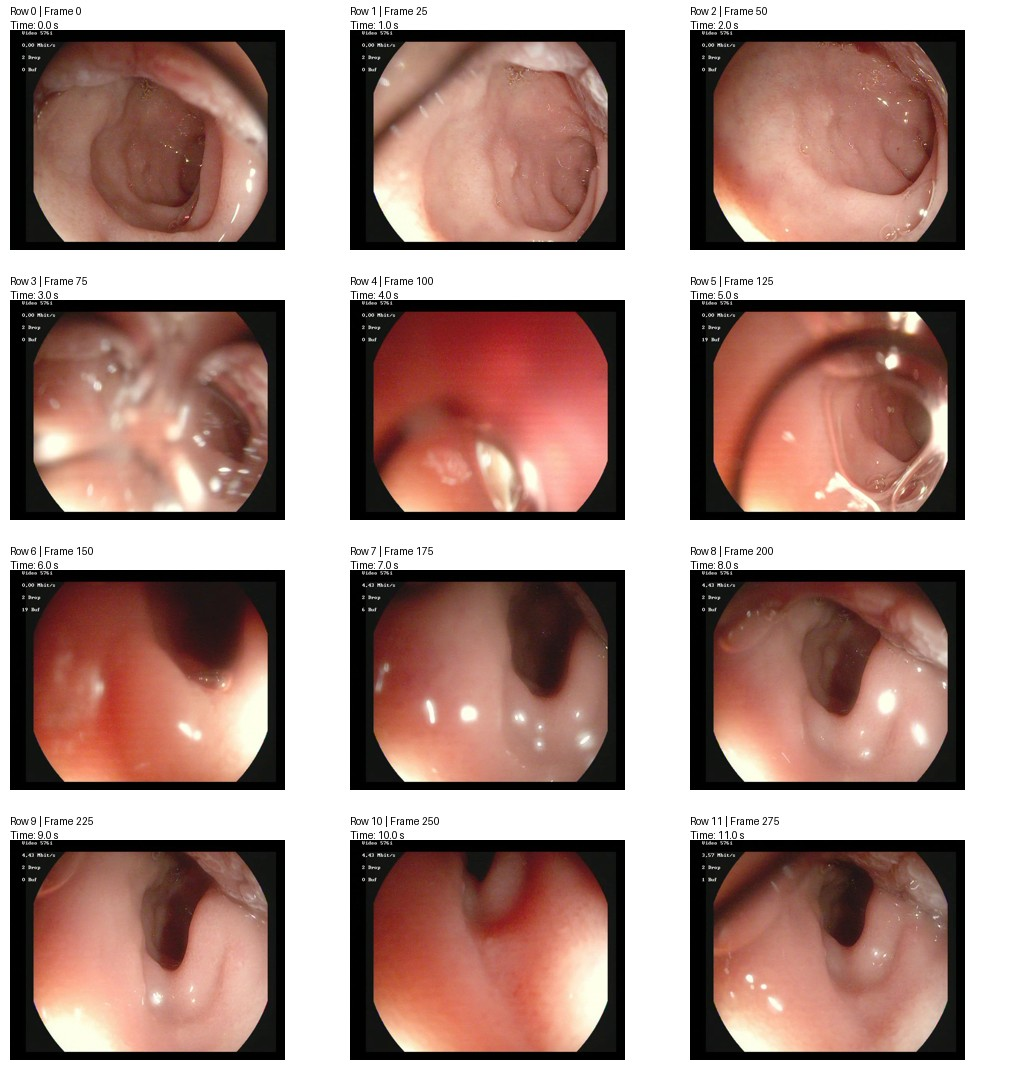

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import math

# ---------------- PATHS ----------------
VIDEO_DIR = "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/Videos"

EXP_DIR = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)

OUT_DIR = os.path.join(EXP_DIR, "frame_annotations")
FRAME_DIR = os.path.join(OUT_DIR, "sampled_frames")

os.makedirs(FRAME_DIR, exist_ok=True)

VIDEO_FILES = [
    "512722d1-05f9-4454-a343-7aba1fb462c2.avi",
    "df1aa095-0cab-4433-97fe-00d456f33615.avi"
]

# Sample every 25th frame: approximately 148 frames total.
SAMPLE_EVERY = 25
THUMBNAIL_SIZE = (320, 220)
FRAMES_PER_SHEET = 12

manifest = []

# ---------------- EXTRACT FRAMES ----------------
for video_name in VIDEO_FILES:
    video_path = os.path.join(VIDEO_DIR, video_name)

    if not os.path.exists(video_path):
        print(f"ERROR: Video not found: {video_path}")
        continue

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"ERROR: Cannot open video: {video_name}")
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    video_id = os.path.splitext(video_name)[0]

    video_out = os.path.join(FRAME_DIR, video_id)
    os.makedirs(video_out, exist_ok=True)

    sampled_count = 0

    for frame_idx in range(0, total_frames, SAMPLE_EVERY):
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ok, frame = cap.read()

        if not ok:
            continue

        frame_name = f"frame_{frame_idx:06d}.jpg"
        frame_path = os.path.join(video_out, frame_name)

        cv2.imwrite(frame_path, frame, [cv2.IMWRITE_JPEG_QUALITY, 90])

        manifest.append({
            "video_id": video_id,
            "video_file": video_name,
            "frame_index": frame_idx,
            "timestamp_seconds": round(frame_idx / fps, 2) if fps else None,
            "frame_path": frame_path,
            "manual_label": "",
            "notes": ""
        })

        sampled_count += 1

    cap.release()
    print(f"{video_name}: sampled {sampled_count} frames")

# ---------------- SAVE ANNOTATION CSV ----------------
df = pd.DataFrame(manifest)
csv_path = os.path.join(OUT_DIR, "manual_frame_annotations.csv")
df.to_csv(csv_path, index=False)

print(f"\nTotal sampled frames: {len(df)}")
print(f"Annotation CSV: {csv_path}")

# ---------------- GENERATE CONTACT SHEETS ----------------
sheet_dir = os.path.join(OUT_DIR, "contact_sheets")
os.makedirs(sheet_dir, exist_ok=True)

for start in range(0, len(df), FRAMES_PER_SHEET):
    batch = df.iloc[start:start + FRAMES_PER_SHEET]

    cols = 3
    rows = math.ceil(len(batch) / cols)
    cell_w, cell_h = 340, 270

    sheet = Image.new(
        "RGB",
        (cols * cell_w, rows * cell_h),
        "white"
    )
    draw = ImageDraw.Draw(sheet)

    for j, (_, item) in enumerate(batch.iterrows()):
        img = Image.open(item["frame_path"]).convert("RGB")
        img.thumbnail(THUMBNAIL_SIZE)

        x = (j % cols) * cell_w
        y = (j // cols) * cell_h

        sheet.paste(img, (x + 10, y + 30))
        caption = (
            f"Row {start + j} | Frame {item['frame_index']}\n"
            f"Time: {item['timestamp_seconds']} s"
        )
        draw.text((x + 10, y + 5), caption, fill="black")

    sheet_name = f"sheet_{start:04d}_{start + len(batch) - 1:04d}.jpg"
    sheet_path = os.path.join(sheet_dir, sheet_name)
    sheet.save(sheet_path, quality=90)

print(f"Contact sheets saved to: {sheet_dir}")

# Show the first sheet as a quick check
if len(df):
    first_sheet = sorted(os.listdir(sheet_dir))[0]
    display(Image.open(os.path.join(sheet_dir, first_sheet)))

In [ ]:
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output, Image as IPyImage

CSV_PATH = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM/"
    "frame_annotations/manual_frame_annotations.csv"
)

df = pd.read_csv(CSV_PATH)
df["manual_label"] = df["manual_label"].fillna("").astype(str)

indices = list(range(min(12, len(df))))
position = [0]  # Mutable position; no global declaration needed

out = widgets.Output()
status = widgets.HTML()
VALID = {"polyp_visible", "polyp_not_visible", "uncertain"}

label_buttons = [
    widgets.Button(description="Polyp visible", button_style="success"),
    widgets.Button(description="Polyp not visible", button_style="info"),
    widgets.Button(description="Uncertain", button_style="warning"),
]

previous = widgets.Button(description="← Previous")
next_frame = widgets.Button(description="Next →")

def save_and_show():
    idx = indices[position[0]]
    row = df.iloc[idx]

    with out:
        clear_output(wait=True)
        print(
            f"Frame {position[0] + 1}/{len(indices)} | "
            f"Frame index: {row['frame_index']} | "
            f"Time: {row['timestamp_seconds']} seconds"
        )

        with open(row["frame_path"], "rb") as f:
            display(IPyImage(data=f.read(), format="jpeg"))

        print("Current label:", row["manual_label"].strip() or "Not labelled")

    count = sum(
        df.iloc[i]["manual_label"].strip() in VALID
        for i in indices
    )
    status.value = f"<b>Labelled: {count}/{len(indices)}</b>"

def choose_label(label):
    idx = indices[position[0]]
    df.at[idx, "manual_label"] = label
    df.to_csv(CSV_PATH, index=False)

    if position[0] < len(indices) - 1:
        position[0] += 1

    save_and_show()

def go_previous(_):
    position[0] = max(0, position[0] - 1)
    save_and_show()

def go_next(_):
    position[0] = min(len(indices) - 1, position[0] + 1)
    save_and_show()

for button, label in zip(
    label_buttons,
    ["polyp_visible", "polyp_not_visible", "uncertain"]
):
    button.on_click(lambda _, value=label: choose_label(value))

previous.on_click(go_previous)
next_frame.on_click(go_next)

display(status, out, widgets.HBox(label_buttons))
display(widgets.HBox([previous, next_frame]))
save_and_show()

HTML(value='')

Output()

FPS: 25.00406316026354
Total video frames: 1263
Sampled frames: 51
Saved CSV: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/frame_annotations/polyp_interval_40_50s/annotations_40_50s.csv


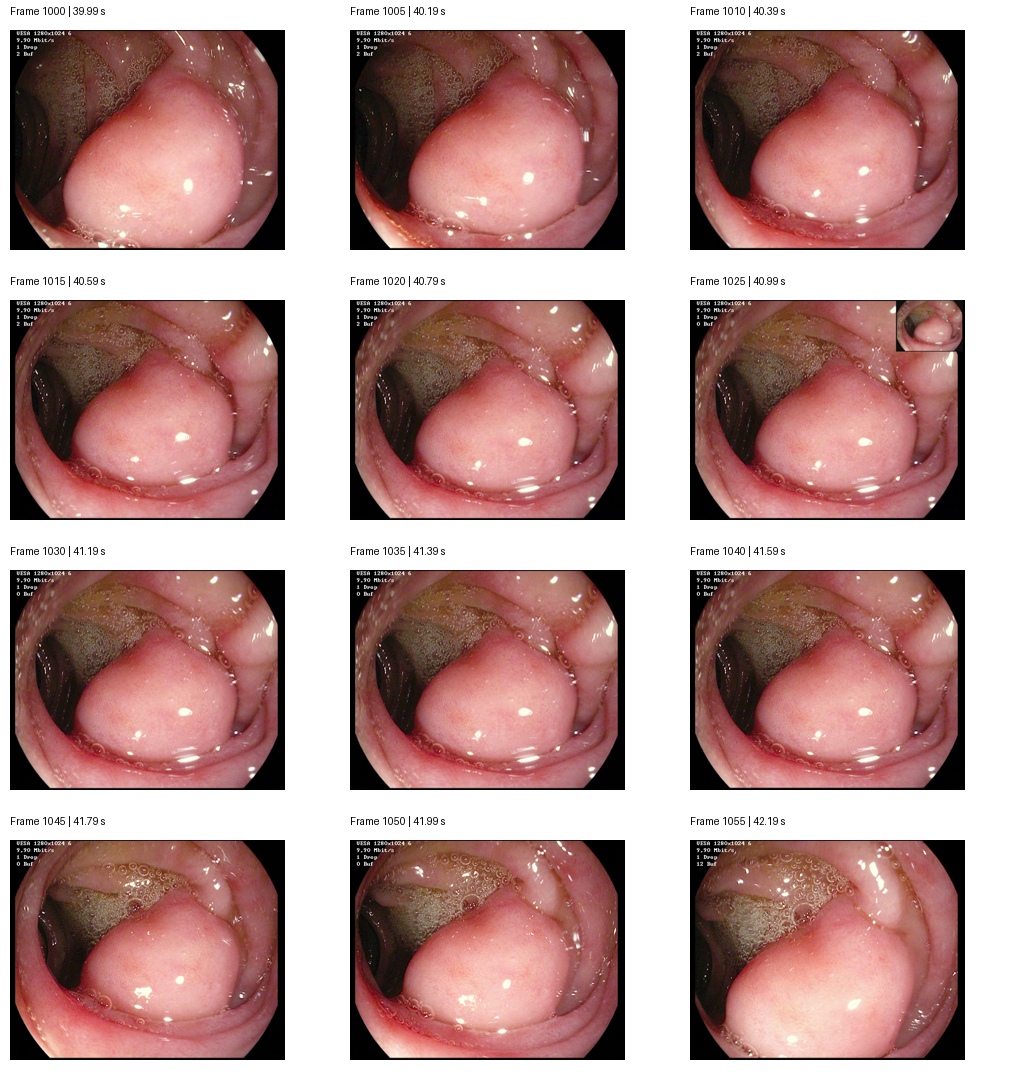

In [ ]:
import os
import cv2
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display

VIDEO_PATH = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/Videos/"
    "df1aa095-0cab-4433-97fe-00d456f33615.avi"
)

EXP_DIR = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)

OUT_DIR = os.path.join(
    EXP_DIR, "frame_annotations", "polyp_interval_40_50s"
)
os.makedirs(OUT_DIR, exist_ok=True)

cap = cv2.VideoCapture(VIDEO_PATH)
assert cap.isOpened(), f"Could not open the second video at path: {VIDEO_PATH}"

fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

start_frame = int(40 * fps)
end_frame = min(int(50 * fps), total - 1)
step = 5

records = []

for frame_idx in range(start_frame, end_frame + 1, step):
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ok, frame = cap.read()

    if not ok:
        continue

    filename = f"frame_{frame_idx:06d}.jpg"
    path = os.path.join(OUT_DIR, filename)
    cv2.imwrite(path, frame)

    records.append({
        "frame_index": frame_idx,
        "timestamp_seconds": round(frame_idx / fps, 2),
        "frame_path": path,
        "manual_label": "",
        "notes": ""
    })

cap.release()

sample_df = pd.DataFrame(records)
csv_path = os.path.join(OUT_DIR, "annotations_40_50s.csv")
sample_df.to_csv(csv_path, index=False)

print("FPS:", fps)
print("Total video frames:", total)
print("Sampled frames:", len(sample_df))
print("Saved CSV:", csv_path)

# Display a contact sheet of the first 12 sampled frames
batch = sample_df.head(12)
cols, cell_w, cell_h = 3, 340, 270
rows = (len(batch) + cols - 1) // cols

sheet = Image.new("RGB", (cols * cell_w, rows * cell_h), "white")
draw = ImageDraw.Draw(sheet)

for j, (_, row) in enumerate(batch.iterrows()):
    img = Image.open(row["frame_path"]).convert("RGB")
    img.thumbnail((320, 220))

    x = (j % cols) * cell_w
    y = (j // cols) * cell_h

    sheet.paste(img, (x + 10, y + 30))
    draw.text(
        (x + 10, y + 5),
        f"Frame {row['frame_index']} | {row['timestamp_seconds']} s",
        fill="black"
    )

display(sheet)

In [ ]:
import os
import cv2
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display

VIDEO_PATH = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/Videos/"
    "df1aa095-0cab-4433-97fe-00d456f33615.avi"
)

OUT_DIR = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM/"
    "frame_annotations/polyp_interval_42_50s"
)
os.makedirs(OUT_DIR, exist_ok=True)

cap = cv2.VideoCapture(VIDEO_PATH)
assert cap.isOpened(), "Could not open video"

fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

records = []

for frame_idx in range(int(42 * fps), min(int(50 * fps), total - 1) + 1, 10):
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ok, frame = cap.read()
    if not ok:
        continue

    path = os.path.join(OUT_DIR, f"frame_{frame_idx:06d}.jpg")
    cv2.imwrite(path, frame)

    records.append({
        "frame_index": frame_idx,
        "timestamp_seconds": round(frame_idx / fps, 2),
        "frame_path": path
    })

cap.release()

df = pd.DataFrame(records)
df.to_csv(os.path.join(OUT_DIR, "sampled_frames.csv"), index=False)

cols, cell_w, cell_h = 3, 340, 270
rows = (len(df) + cols - 1) // cols
sheet = Image.new("RGB", (cols * cell_w, rows * cell_h), "white")
draw = ImageDraw.Draw(sheet)

for i, row in df.iterrows():
    img = Image.open(row["frame_path"]).convert("RGB")
    img.thumbnail((320, 220))
    x, y = (i % cols) * cell_w, (i // cols) * cell_h
    sheet.paste(img, (x + 10, y + 30))
    draw.text(
        (x + 10, y + 5),
        f"Frame {row['frame_index']} | {row['timestamp_seconds']} s",
        fill="black"
    )

display(sheet)
print("Sampled frames:", len(df))

In [ ]:
import os
import glob
import pandas as pd

EXP_DIR = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)

for folder in [
    "raw_video_predictions",
    "hmm_video_predictions"
]:
    path = os.path.join(EXP_DIR, folder)
    print(f"\n--- {folder} ---")

    for file in glob.glob(os.path.join(path, "*.csv")):
        df = pd.read_csv(file)
        print("\nFile:", os.path.basename(file))
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(2).to_string(index=False))


--- raw_video_predictions ---

File: 512722d1-05f9-4454-a343-7aba1fb462c2_predictions.csv
Shape: (2421, 7)
Columns: ['video', 'frame', 'timestamp_seconds', 'detected', 'max_confidence', 'num_detections', 'boxes_xyxy']
                                   video  frame  timestamp_seconds  detected  max_confidence  num_detections boxes_xyxy
512722d1-05f9-4454-a343-7aba1fb462c2.avi      0               0.00         0             0.0               0         []
512722d1-05f9-4454-a343-7aba1fb462c2.avi      1               0.04         0             0.0               0         []

File: df1aa095-0cab-4433-97fe-00d456f33615_predictions.csv
Shape: (1263, 7)
Columns: ['video', 'frame', 'timestamp_seconds', 'detected', 'max_confidence', 'num_detections', 'boxes_xyxy']
                                   video  frame  timestamp_seconds  detected  max_confidence  num_detections boxes_xyxy
df1aa095-0cab-4433-97fe-00d456f33615.avi      0               0.00         0             0.0               0     

VIDEO: df1aa095-0cab-4433-97fe-00d456f33615.avi
Frames analysed: 251
Time range: 39.99–49.99 seconds

E3 at HMM confidence threshold
Positive frames: 31/251
Positive proportion: 12.4%
State changes: 27

E4 HMM state
Positive frames: 24/251
Positive proportion: 9.6%
State changes: 11

E3/E4 agreement:
E4     0   1  All
E3               
0    217   3  220
1     10  21   31
All  227  24  251

Per-second results:


,second,frames,E3_positive_frames,E4_positive_frames,mean_E3_confidence,mean_E4_probability
0,39,1,1,1,0.637,0.992
1,40,25,9,10,0.396,0.395
2,41,25,3,1,0.251,0.075
3,42,25,5,5,0.219,0.183
4,43,25,0,0,0.038,0.004
5,44,25,1,0,0.280,0.016
6,45,25,3,0,0.317,0.040
7,46,25,0,0,0.245,0.005
8,47,25,4,2,0.245,0.110
9,48,25,4,5,0.107,0.179


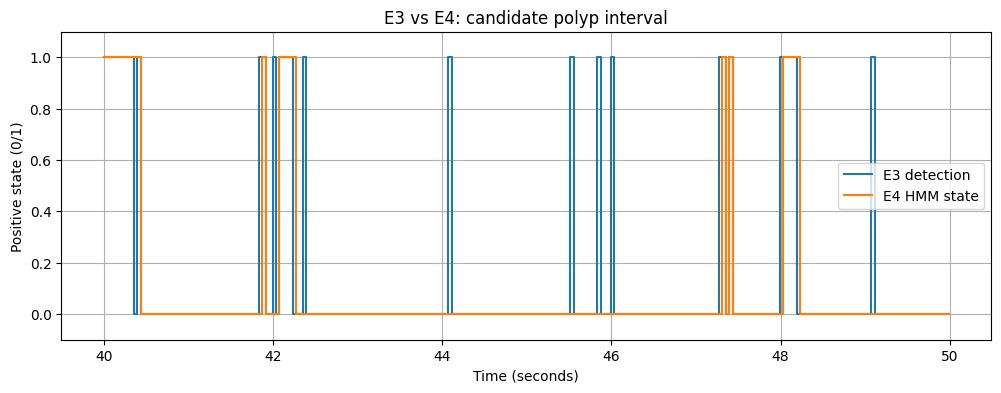


First 20 frames where E3 and E4 disagree:


,frame,timestamp_seconds,max_confidence,num_detections,E3_positive,E4_positive,e4_polyp_probability
1009,1009,40.3534,0.4759,1,0,1,0.5312
1046,1046,41.8332,0.5939,1,1,0,0.2794
1050,1050,41.9932,0.6238,1,1,0,0.4241
1056,1056,42.2331,0.2747,2,0,1,0.5294
1059,1059,42.3531,0.5296,1,1,0,0.3342
1102,1102,44.0728,0.5937,2,1,0,0.2794
1138,1138,45.5126,0.5205,1,1,0,0.2794
1146,1146,45.8326,0.5054,1,1,0,0.2794
1150,1150,45.9925,0.5109,1,1,0,0.2816
1182,1182,47.2723,0.5504,1,1,0,0.2794


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

EXP_DIR = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)

VIDEO_ID = "df1aa095-0cab-4433-97fe-00d456f33615.avi"

RAW_PATH = os.path.join(
    EXP_DIR, "raw_video_predictions",
    "df1aa095-0cab-4433-97fe-00d456f33615_predictions.csv"
)

HMM_PATH = os.path.join(
    EXP_DIR, "hmm_video_predictions",
    "df1aa095-0cab-4433-97fe-00d456f33615_e4_hmm.csv"
)

raw = pd.read_csv(RAW_PATH)
hmm = pd.read_csv(HMM_PATH)

# Focus on approximately 40–50 seconds.
# Frames 1000–1250 correspond to 40–50 seconds at 25 FPS.
start_frame, end_frame = 1000, 1250

cols = [
    "frame", "timestamp_seconds", "max_confidence",
    "num_detections", "e3_detected_at_hmm_threshold",
    "e4_hmm_state", "e4_polyp_probability"
]

segment = hmm.loc[
    hmm["frame"].between(start_frame, end_frame),
    cols
].copy()

segment["E3_positive"] = (
    segment["e3_detected_at_hmm_threshold"].astype(int)
)
segment["E4_positive"] = segment["e4_hmm_state"].astype(int)

# ---------------- SUMMARY ----------------
def transitions(values):
    values = values.astype(int)
    return int(values.diff().fillna(0).ne(0).sum())

print("VIDEO:", VIDEO_ID)
print("Frames analysed:", len(segment))
print(
    f"Time range: {segment['timestamp_seconds'].min():.2f}–"
    f"{segment['timestamp_seconds'].max():.2f} seconds"
)

for name, col in [
    ("E3 at HMM confidence threshold", "E3_positive"),
    ("E4 HMM state", "E4_positive")
]:
    positive = int(segment[col].sum())
    print(f"\n{name}")
    print(f"Positive frames: {positive}/{len(segment)}")
    print(f"Positive proportion: {positive / len(segment):.1%}")
    print(f"State changes: {transitions(segment[col])}")

print("\nE3/E4 agreement:")
print(pd.crosstab(
    segment["E3_positive"],
    segment["E4_positive"],
    rownames=["E3"],
    colnames=["E4"],
    margins=True
))

# ---------------- PER-SECOND SUMMARY ----------------
segment["second"] = segment["timestamp_seconds"].astype(int)

per_second = segment.groupby("second").agg(
    frames=("frame", "count"),
    E3_positive_frames=("E3_positive", "sum"),
    E4_positive_frames=("E4_positive", "sum"),
    mean_E3_confidence=("max_confidence", "mean"),
    mean_E4_probability=("e4_polyp_probability", "mean")
).reset_index()

print("\nPer-second results:")
display(per_second.round(3))

# ---------------- PLOT ----------------
plt.figure(figsize=(12, 4))
plt.step(
    segment["timestamp_seconds"],
    segment["E3_positive"],
    where="post",
    label="E3 detection",
)
plt.step(
    segment["timestamp_seconds"],
    segment["E4_positive"],
    where="post",
    label="E4 HMM state",
)
plt.xlabel("Time (seconds)")
plt.ylabel("Positive state (0/1)")
plt.title("E3 vs E4: candidate polyp interval")
plt.ylim(-0.1, 1.1)
plt.grid(True)
plt.legend()
plt.show()

# ---------------- DISAGREEMENTS ----------------
disagreements = segment[
    segment["E3_positive"] != segment["E4_positive"]
][[
    "frame", "timestamp_seconds", "max_confidence",
    "num_detections", "E3_positive", "E4_positive",
    "e4_polyp_probability"
]]

print("\nFirst 20 frames where E3 and E4 disagree:")
display(disagreements.head(20).round(4))

In [ ]:
import os
import cv2
import pandas as pd
from PIL import Image
from IPython.display import display

EXP_DIR = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)

VIDEO_PATH = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/Videos/"
    "df1aa095-0cab-4433-97fe-00d456f33615.avi"
)

PRED_PATH = os.path.join(
    EXP_DIR, "hmm_video_predictions",
    "df1aa095-0cab-4433-97fe-00d456f33615_e4_hmm.csv"
)

OUT_DIR = os.path.join(EXP_DIR, "e3_e4_visual_inspection")
os.makedirs(OUT_DIR, exist_ok=True)

pred = pd.read_csv(PRED_PATH)
cap = cv2.VideoCapture(VIDEO_PATH)

frames_to_check = [1009, 1046, 1056, 1146, 1200]

for frame_idx in frames_to_check:
    row = pred.loc[pred["frame"] == frame_idx].iloc[0]

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ok, frame = cap.read()

    if not ok:
        print("Could not read frame:", frame_idx)
        continue

    # Draw saved E3 bounding boxes.
    boxes = row["boxes_xyxy"]
    if isinstance(boxes, str) and boxes.strip() not in ("", "[]"):
        import ast
        parsed = ast.literal_eval(boxes)

        for box in parsed:
            x1, y1, x2, y2 = map(int, box[:4])
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 3)

    e3 = int(row["e3_detected_at_hmm_threshold"])
    e4 = int(row["e4_hmm_state"])
    conf = float(row["max_confidence"])
    prob = float(row["e4_polyp_probability"])

    caption = (
        f"Frame {frame_idx} | {row['timestamp_seconds']:.2f}s | "
        f"E3={e3} conf={conf:.2f} | E4={e4} prob={prob:.2f}"
    )
    cv2.putText(
        frame, caption, (20, 35),
        cv2.FONT_HERSHEY_SIMPLEX, 0.65,
        (255, 255, 255), 2, cv2.LINE_AA
    )

    out_path = os.path.join(OUT_DIR, f"frame_{frame_idx}.jpg")
    cv2.imwrite(out_path, frame)

    print(caption)
    display(Image.open(out_path))

cap.release()
print("Saved images to:", OUT_DIR)

In [ ]:
import pandas as pd
import os

EXP_DIR = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)

csv_path = os.path.join(
    EXP_DIR,
    "raw_video_predictions",
    "df1aa095-0cab-4433-97fe-00d456f33615_predictions.csv"
)

df = pd.read_csv(csv_path)

# Examine the interval where you observed the protrusion.
interval = df[
    (df["timestamp_seconds"] >= 39.99) &
    (df["timestamp_seconds"] <= 49.99)
].copy()

print("Frames in interval:", len(interval))
print("Original detections:", int(interval["detected"].sum()))
print()

for threshold in [0.25, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    positives = (
        (interval["num_detections"] > 0) &
        (interval["max_confidence"] >= threshold)
    ).sum()

    print(
        f"Threshold {threshold:.2f}: "
        f"{positives}/{len(interval)} positive frames "
        f"({100 * positives / len(interval):.1f}%)"
    )

Frames in interval: 250
Original detections: 130

Threshold 0.25: 130/250 positive frames (52.0%)
Threshold 0.35: 80/250 positive frames (32.0%)
Threshold 0.40: 59/250 positive frames (23.6%)
Threshold 0.45: 41/250 positive frames (16.4%)
Threshold 0.50: 31/250 positive frames (12.4%)
Threshold 0.55: 24/250 positive frames (9.6%)
Threshold 0.60: 16/250 positive frames (6.4%)


In [ ]:
import pandas as pd
import os

EXP_DIR = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)

csv_path = os.path.join(
    EXP_DIR,
    "raw_video_predictions",
    "df1aa095-0cab-4433-97fe-00d456f33615_predictions.csv"
)

df = pd.read_csv(csv_path)

interval = df[
    (df["timestamp_seconds"] >= 39.99) &
    (df["timestamp_seconds"] <= 49.99)
].copy().sort_values("frame")

print("Threshold | Positive frames | State changes | Changes/second")
print("-" * 65)

duration = (
    interval["timestamp_seconds"].max()
    - interval["timestamp_seconds"].min()
)

for threshold in [0.25, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    state = (
        (interval["num_detections"] > 0) &
        (interval["max_confidence"] >= threshold)
    ).astype(int)

    positives = int(state.sum())
    changes = int(state.diff().abs().fillna(0).sum())
    changes_per_second = changes / duration if duration > 0 else 0

    print(
        f"{threshold:>8.2f} | "
        f"{positives:>15} | "
        f"{changes:>13} | "
        f"{changes_per_second:>14.2f}"
    )

Threshold | Positive frames | State changes | Changes/second
-----------------------------------------------------------------
    0.25 |             130 |            67 |           6.73
    0.35 |              80 |            67 |           6.73
    0.40 |              59 |            51 |           5.12
    0.45 |              41 |            33 |           3.31
    0.50 |              31 |            27 |           2.71
    0.55 |              24 |            15 |           1.51
    0.60 |              16 |            17 |           1.71


In [ ]:
import os
import cv2
import ast
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. File paths
# --------------------------------------------------

BASE_DIR = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)

VIDEO_PATH = os.path.join(
    BASE_DIR,
    "Videos",
    "df1aa095-0cab-4433-97fe-00d456f33615.avi"
)

RAW_CSV = os.path.join(
    BASE_DIR,
    "raw_video_predictions",
    "df1aa095-0cab-4433-97fe-00d456f33615_predictions.csv"
)

HMM_CSV = os.path.join(
    BASE_DIR,
    "hmm_video_predictions",
    "df1aa095-0cab-4433-97fe-00d456f33615_e4_hmm.csv"
)

OUTPUT_PATH = "/content/E3_threshold_comparison.mp4"

# --------------------------------------------------
# 2. Validate files and load predictions
# --------------------------------------------------

for path in [VIDEO_PATH, RAW_CSV, HMM_CSV]:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing input file: {path}")

raw_df = pd.read_csv(RAW_CSV).sort_values("frame")
hmm_df = pd.read_csv(HMM_CSV).sort_values("frame")

required_raw = {
    "frame", "timestamp_seconds", "max_confidence",
    "num_detections", "boxes_xyxy"
}

required_hmm = {"frame", "e4_hmm_state"}

if not required_raw.issubset(raw_df.columns):
    raise ValueError(
        f"Missing raw prediction columns: "
        f"{required_raw - set(raw_df.columns)}"
    )

if not required_hmm.issubset(hmm_df.columns):
    raise ValueError(
        f"Missing HMM columns: "
        f"{required_hmm - set(hmm_df.columns)}"
    )

raw_map = {
    int(row["frame"]): row
    for _, row in raw_df.iterrows()
}

hmm_map = {
    int(row["frame"]): row
    for _, row in hmm_df.iterrows()
}

# --------------------------------------------------
# 3. Helper functions
# --------------------------------------------------

def parse_boxes(value):
    try:
        result = ast.literal_eval(str(value))
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError, TypeError):
        return []


def draw_panel(frame, title, detected, confidence, boxes):
    panel = frame.copy()

    if detected:
        for box in boxes:
            if len(box) < 4:
                continue

            x1, y1, x2, y2 = map(int, box[:4])

            cv2.rectangle(
                panel,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

    status = "DETECTION" if detected else "NO DETECTION"

    cv2.putText(
        panel,
        title,
        (10, 25),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.58,
        (255, 255, 255),
        1,
        cv2.LINE_AA
    )

    cv2.putText(
        panel,
        f"{status} | Conf: {confidence:.2f}",
        (10, 48),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.43,
        (0, 255, 0) if detected else (0, 0, 255),
        1,
        cv2.LINE_AA
    )

    return panel


# --------------------------------------------------
# 4. Open input and initialize output video
# --------------------------------------------------

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Cannot open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)

if not np.isfinite(fps) or fps <= 0:
    fps = 25.0

original_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
original_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

panel_width = 640
panel_height = int(
    original_height * panel_width / original_width
)

header_height = 65

output_width = panel_width * 3
output_height = panel_height + header_height

os.makedirs(os.path.dirname(OUTPUT_PATH), exist_ok=True)

writer = cv2.VideoWriter(
    OUTPUT_PATH,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (output_width, output_height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not initialize MP4 writer.")

# --------------------------------------------------
# 5. Generate E3 / E3 / E4 comparison
# --------------------------------------------------

THRESHOLD_040 = 0.40
THRESHOLD_050 = 0.50

frame_index = 0

while True:
    success, frame = cap.read()

    if not success:
        break

    raw_row = raw_map.get(frame_index)
    hmm_row = hmm_map.get(frame_index)

    confidence = (
        float(raw_row["max_confidence"])
        if raw_row is not None else 0.0
    )

    num_detections = (
        int(raw_row["num_detections"])
        if raw_row is not None else 0
    )

    boxes = (
        parse_boxes(raw_row["boxes_xyxy"])
        if raw_row is not None else []
    )

    # E3 binary decisions at two confidence thresholds
    e3_040 = (
        num_detections > 0
        and confidence >= THRESHOLD_040
    )

    e3_050 = (
        num_detections > 0
        and confidence >= THRESHOLD_050
    )

    # Actual state produced by the E4 HMM
    e4_state = (
        int(hmm_row["e4_hmm_state"])
        if hmm_row is not None else 0
    )

    # Resize the original frame once for all panels
    original = cv2.resize(
        frame,
        (panel_width, panel_height)
    )

    left_panel = draw_panel(
        original,
        "E3 threshold 0.40",
        e3_040,
        confidence,
        boxes
    )

    middle_panel = draw_panel(
        original,
        "E3 threshold 0.50",
        e3_050,
        confidence,
        boxes
    )

    right_panel = draw_panel(
        original,
        f"E4 HMM | E4={e4_state}",
        bool(e4_state),
        confidence,
        boxes if e4_state else []
    )

    # Black background and top frame/timestamp label
    canvas = np.zeros(
        (output_height, output_width, 3),
        dtype=np.uint8
    )

    timestamp = frame_index / fps

    cv2.putText(
        canvas,
        f"Frame {frame_index} | {timestamp:.2f}s",
        (8, 42),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 255, 255),
        1,
        cv2.LINE_AA
    )

    y = header_height

    canvas[y:y + panel_height, 0:panel_width] = left_panel

    canvas[
        y:y + panel_height,
        panel_width:panel_width * 2
    ] = middle_panel

    canvas[
        y:y + panel_height,
        panel_width * 2:panel_width * 3
    ] = right_panel

    writer.write(canvas)
    frame_index += 1

cap.release()
writer.release()

# --------------------------------------------------
# 6. Verify output
# --------------------------------------------------

if not os.path.isfile(OUTPUT_PATH):
    raise RuntimeError("Output video was not created.")

file_size = os.path.getsize(OUTPUT_PATH)

if file_size == 0:
    raise RuntimeError("Output video is empty.")

print("Three-panel comparison video generated.")
print("Output:", OUTPUT_PATH)
print("Frames processed:", frame_index)
print("FPS:", round(fps, 2))
print("Resolution:", f"{output_width} x {output_height}")
print("File size:", round(file_size / (1024 * 1024), 2), "MB")

Three-panel comparison video generated.
Output: /content/E3_threshold_comparison.mp4
Frames processed: 1263
FPS: 25.0
Resolution: 1920 x 577
File size: 116.44 MB


In [ ]:
import os
import shutil

destination = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM/"
    "threshold_comparison/E3_threshold_comparison.mp4"
)

os.makedirs(os.path.dirname(destination), exist_ok=True)
shutil.copy2("/content/E3_threshold_comparison.mp4", destination)

print("Saved to Drive:", destination)
print("File size (MB):", round(os.path.getsize(destination) / 1024**2, 2))

Saved to Drive: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/threshold_comparison/E3_threshold_comparison.mp4
File size (MB): 116.44


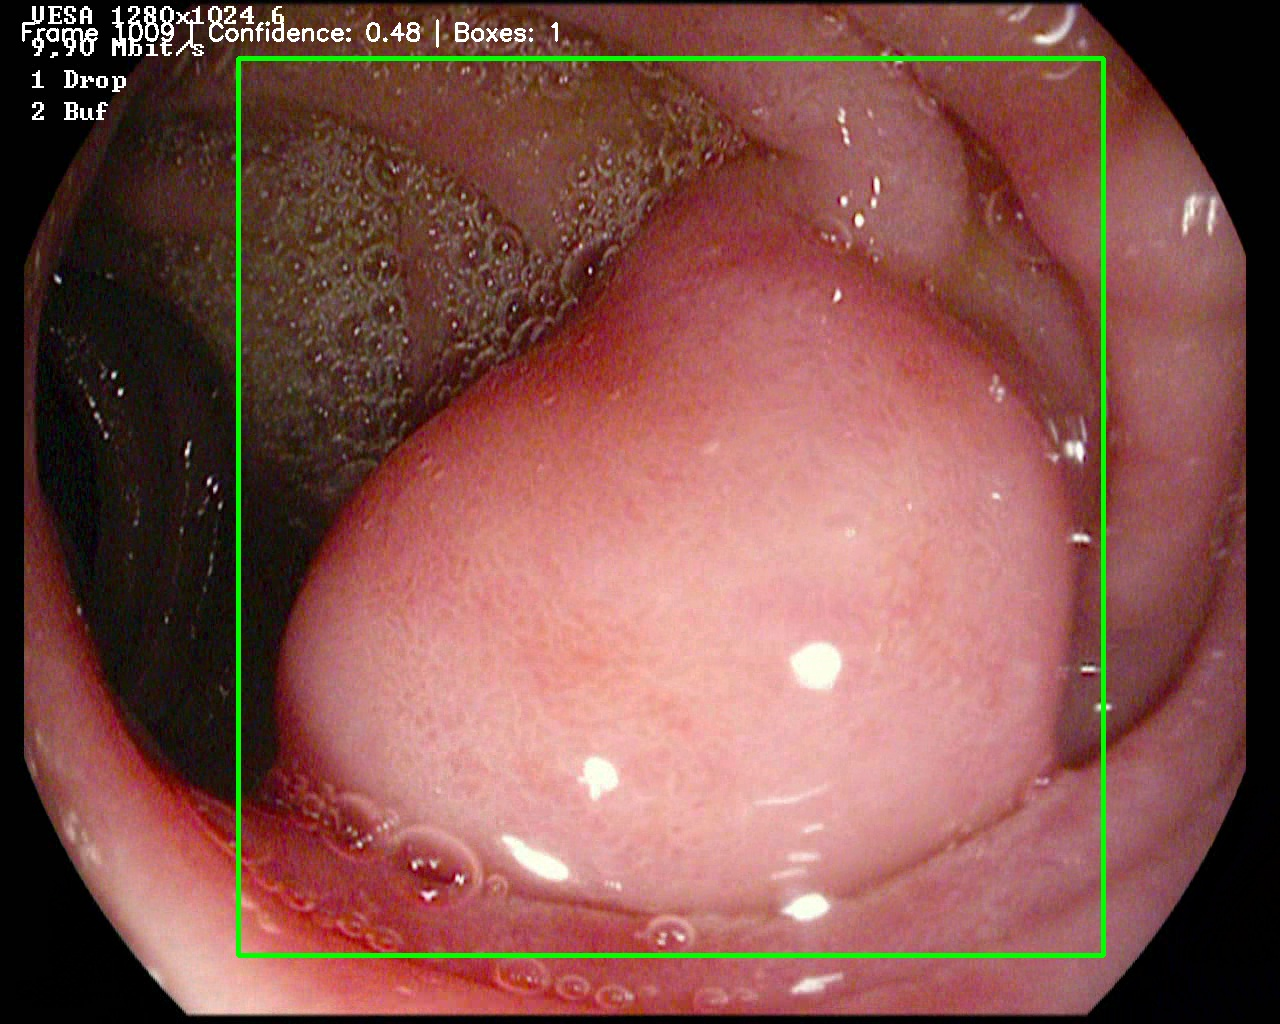

Saved boxes: [[238.70388793945312, 58.85540771484375, 1103.879150390625, 955.3663940429688]]


In [ ]:
import os
import cv2
import ast
import pandas as pd
from IPython.display import display, Image

BASE = "/content/drive/MyDrive/Capsule_Perception"
EXP_DIR = os.path.join(
    BASE, "experiments",
    "Professor_Fresh_Run",
    "E4_Final_HMM"
)

VIDEO_PATH = os.path.join(
    BASE, "experiments", "Professor_Fresh_Run", "E4_Final_HMM", "Videos",
    "df1aa095-0cab-4433-97fe-00d456f33615.avi"
)

CSV_PATH = os.path.join(
    EXP_DIR, "raw_video_predictions",
    "df1aa095-0cab-4433-97fe-00d456f33615_predictions.csv"
)

df = pd.read_csv(CSV_PATH)

# Frame 1009 is approximately 40.35 seconds.
FRAME_IDX = 1009
row = df.loc[df["frame"] == FRAME_IDX].iloc[0]

cap = cv2.VideoCapture(VIDEO_PATH)
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
ok, frame = cap.read()
cap.release()

assert ok, "Could not read source frame."

boxes = ast.literal_eval(row["boxes_xyxy"])

for box in boxes:
    x1, y1, x2, y2 = map(int, box)
    cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 3)

label = (
    f"Frame {FRAME_IDX} | "
    f"Confidence: {row['max_confidence']:.2f} | "
    f"Boxes: {len(boxes)}"
)
cv2.putText(
    frame, label, (20, 40),
    cv2.FONT_HERSHEY_SIMPLEX, 0.8,
    (255, 255, 255), 2
)

display(Image(data=cv2.imencode(".jpg", frame)[1].tobytes()))
print("Saved boxes:", boxes)

In [ ]:
import os
import cv2
import ast
import pandas as pd
import numpy as np
from IPython.display import Video, display

BASE = "/content/drive/MyDrive/Capsule_Perception"
EXP = os.path.join(
    BASE, "experiments",
    "Professor_Fresh_Run",
    "E4_Final_HMM"
)

VIDEO = os.path.join(
    BASE, "experiments", "Professor_Fresh_Run", "E4_Final_HMM", "Videos",
    "df1aa095-0cab-4433-97fe-00d456f33615.avi"
)

RAW = pd.read_csv(os.path.join(
    EXP, "raw_video_predictions",
    "df1aa095-0cab-4433-97fe-00d456f33615_predictions.csv"
)).set_index("frame")

HMM = pd.read_csv(os.path.join(
    EXP, "hmm_video_predictions",
    "df1aa095-0cab-4433-97fe-00d456f33615_e4_hmm.csv"
)).set_index("frame")

cap = cv2.VideoCapture(VIDEO)
assert cap.isOpened(), "Cannot open source video"

fps = cap.get(cv2.CAP_PROP_FPS) or 25
W, H = 480, 384
out_path = "/content/E3_E4_comparison_fixed.mp4"

writer = cv2.VideoWriter(
    out_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (W * 3, H + 40)
)
assert writer.isOpened(), "Cannot initialize writer"

def boxes_from(value):
    if not isinstance(value, str) or value.strip() in ("", "[]"):
        return []
    return ast.literal_eval(value)

def draw_panel(frame, row, threshold, title, e4=None):
    img = cv2.resize(frame, (W, H))
    conf = float(row["max_confidence"])
    boxes = boxes_from(row["boxes_xyxy"])

    # max_confidence is frame-level, not per-box confidence.
    # Thus this filters the entire frame, not individual boxes.
    if conf >= threshold:
        for box in boxes:
            x1, y1, x2, y2 = map(float, box[:4])
            x1, x2 = int(x1 * W / 1280), int(x2 * W / 1280)
            y1, y2 = int(y1 * H / 1024), int(y2 * H / 1024)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

    text = f"{title} | conf={conf:.2f}"
    if e4 is not None:
        text += f" | E4={e4}"

    cv2.rectangle(img, (0, 0), (W, 30), (0, 0, 0), -1)
    cv2.putText(img, text, (5, 21),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45,
                (255, 255, 255), 1)
    return img

written = 0

try:
    for idx in range(1000, 1250):
        if idx not in RAW.index or idx not in HMM.index:
            continue

        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if not ok:
            continue

        r = RAW.loc[idx]
        h = HMM.loc[idx]
        e4 = int(h["e4_hmm_state"])

        panels = [
            draw_panel(frame, r, 0.40, "E3 threshold 0.40"),
            draw_panel(frame, r, 0.50, "E3 threshold 0.50"),
            draw_panel(frame, r, 0.50, "E4 HMM", e4)
        ]

        canvas = np.zeros((H + 40, W * 3, 3), dtype=np.uint8)
        canvas[40:, :] = np.hstack(panels)

        t = float(r["timestamp_seconds"])
        cv2.putText(canvas, f"Frame {idx} | {t:.2f}s",
                    (10, 27), cv2.FONT_HERSHEY_SIMPLEX,
                    0.7, (255, 255, 255), 2)

        writer.write(canvas)
        written += 1
finally:
    cap.release()
    writer.release()

check = cv2.VideoCapture(out_path)
ok, first = check.read()
count = int(check.get(cv2.CAP_PROP_FRAME_COUNT))
check.release()

print("Frames written:", written)
print("File size (MB):", round(os.path.getsize(out_path)/1024**2, 2))
print("Verification: readable first frame =", ok, "| frame count =", count)

assert written > 0 and ok, "Video generation failed"

display(Video(out_path, embed=True, width=1100))

In [ ]:
import os
import shutil

source = "/content/E3_E4_comparison_fixed.mp4"

destination = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM/"
    "threshold_comparison/E3_E4_comparison_fixed.mp4"
)

# Ensure Google Drive is mounted
from google.colab import drive
drive.mount("/content/drive")

# Verify the source exists and is not empty
if not os.path.exists(source) or os.path.getsize(source) == 0:
    raise FileNotFoundError("Comparison video is missing or empty.")

# Create destination folder and copy
os.makedirs(os.path.dirname(destination), exist_ok=True)
shutil.copy2(source, destination)

print("Video saved successfully!")
print("Location:", destination)
print("Size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Video saved successfully!
Location: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/threshold_comparison/E3_E4_comparison_fixed.mp4
Size: 15.21 MB


In [ ]:

from pathlib import Path
import json

BASE = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)

config_path = BASE / "hmm_config.json"
script_path = BASE / "hmm_filter.py"

print("=== HMM CONFIGURATION ===")
if config_path.exists():
    print(json.dumps(json.loads(config_path.read_text()), indent=2))
else:
    print("Config file not found:", config_path)

print("\n=== HMM FILTER IMPLEMENTATION ===")
if script_path.exists():
    print(script_path.read_text())
else:
    print("Filter script not found:", script_path)


=== HMM CONFIGURATION ===
{
  "experiment": "E4_Final_HMM",
  "detector": "E3_Sakaguchi_Fractional_DWT",
  "weights": "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E3_Sakaguchi_Fractional_DWT/weights/best.pt",
  "states": {
    "0": "NO_POLYP_SUSPECTED",
    "1": "POLYP_SUSPECTED"
  },
  "transition_probabilities": {
    "no_polyp_to_polyp": 0.03,
    "polyp_to_no_polyp": 0.08
  },
  "emission_probabilities": {
    "detection_given_no_polyp": 0.08,
    "detection_given_polyp": 0.9
  },
  "initial_polyp_probability": 0.05,
  "confidence_threshold": 0.5,
  "probabilities_status": "PROVISIONAL_NOT_CALIBRATED"
}

=== HMM FILTER IMPLEMENTATION ===

import json
from pathlib import Path

class PolypHMM:
    """Causal two-state HMM filter for frame-level YOLO observations."""

    def __init__(self, config_path):
        with open(config_path, "r") as f:
            self.cfg = json.load(f)

        tr = self.cfg["transition_probabilities"]
        em 

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)

VIDEO_ID = "df1aa095-0cab-4433-97fe-00d456f33615"
csv_path = BASE / "raw_video_predictions" / f"{VIDEO_ID}_predictions.csv"

# Find the file if its saved name differs slightly.
if not csv_path.exists():
    matches = list((BASE / "raw_video_predictions").glob(
        f"{VIDEO_ID}*predictions.csv"
    ))
    if not matches:
        raise FileNotFoundError(
            f"Could not find predictions for {VIDEO_ID} in "
            f"{BASE / 'raw_video_predictions'}"
        )
    csv_path = matches[0]

df = pd.read_csv(csv_path).sort_values("frame").reset_index(drop=True)

# Process the entire video so the HMM has preceding temporal context.
# Then evaluate only the 39.99–49.99 second interval.
segment_start, segment_end = 39.99, 49.99
segment = df[
    df["timestamp_seconds"].between(segment_start, segment_end)
].copy()

if segment.empty:
    raise ValueError("No frames found in the requested time interval.")

# HMM variants: keep the baseline, then increase state persistence.
configs = {
    "Baseline": {
        "p01": 0.03, "p10": 0.08,
        "p_detect_0": 0.08, "p_detect_1": 0.90
    },
    "Moderate persistence": {
        "p01": 0.02, "p10": 0.04,
        "p_detect_0": 0.08, "p_detect_1": 0.90
    },
    "Strong persistence": {
        "p01": 0.01, "p10": 0.02,
        "p_detect_0": 0.08, "p_detect_1": 0.90
    }
}

def run_hmm(data, threshold, cfg):
    p0, p1 = 0.95, 0.05
    states, probabilities, observations = [], [], []

    for row in data.itertuples(index=False):
        confidence = float(row.max_confidence)
        has_box = int(row.num_detections) > 0
        detected = has_box and confidence >= threshold

        # Predict hidden state.
        pred0 = p0 * (1 - cfg["p01"]) + p1 * cfg["p10"]
        pred1 = p0 * cfg["p01"] + p1 * (1 - cfg["p10"])

        # Apply binary observation likelihood.
        if detected:
            l0, l1 = cfg["p_detect_0"], cfg["p_detect_1"]
        else:
            l0 = 1 - cfg["p_detect_0"]
            l1 = 1 - cfg["p_detect_1"]

        w0, w1 = pred0 * l0, pred1 * l1
        total = w0 + w1
        p0, p1 = w0 / total, w1 / total

        states.append(int(p1 >= p0))
        probabilities.append(p1)
        observations.append(int(detected))

    return np.array(states), np.array(probabilities), np.array(observations)

results = []

for threshold in [0.40, 0.50]:
    for name, cfg in configs.items():
        states, probs, observations = run_hmm(df, threshold, cfg)

        # Align full-video results to the chosen time interval.
        indices = segment.index.to_numpy()
        local_states = states[indices]
        local_obs = observations[indices]

        changes = int(np.sum(local_states[1:] != local_states[:-1]))
        duration = (
            segment["timestamp_seconds"].iloc[-1]
            - segment["timestamp_seconds"].iloc[0]
        )

        results.append({
            "threshold": threshold,
            "HMM_setting": name,
            "E3_positive_frames": int(local_obs.sum()),
            "E4_positive_frames": int(local_states.sum()),
            "E4_positive_percent": round(100 * local_states.mean(), 2),
            "E4_state_changes": changes,
            "changes_per_second": round(
                changes / duration if duration > 0 else 0, 3
            ),
            "mean_E4_probability": round(
                float(probs[indices].mean()), 4
            )
        })

results_df = pd.DataFrame(results)
display(results_df)

out_path = BASE / "E4_Final_HMM" / "hmm_persistence_threshold_experiment.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)
results_df.to_csv(out_path, index=False)

print("Saved results to:", out_path)
print("\nNote: fewer state changes indicate smoother output,")
print("not necessarily better polyp detection accuracy.")


,threshold,HMM_setting,E3_positive_frames,E4_positive_frames,E4_positive_percent,E4_state_changes,changes_per_second,mean_E4_probability
0,0.4,Baseline,59,48,19.2,31,3.113,0.2095
1,0.4,Moderate persistence,59,53,21.2,25,2.510,0.2141
2,0.4,Strong persistence,59,55,22.0,25,2.510,0.2102
3,0.5,Baseline,31,24,9.6,11,1.105,0.1064
4,0.5,Moderate persistence,31,24,9.6,11,1.105,0.1055
5,0.5,Strong persistence,31,24,9.6,11,1.105,0.1007


Saved results to: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/E4_Final_HMM/hmm_persistence_threshold_experiment.csv

Note: fewer state changes indicate smoother output,
not necessarily better polyp detection accuracy.


In [ ]:

import json
import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)

pred_path = (
    BASE / "raw_video_predictions" /
    "df1aa095-0cab-4433-97fe-00d456f33615_predictions.csv"
)

df = pd.read_csv(pred_path).sort_values("frame").reset_index(drop=True)

# Reuse the actual HMM implementation and override only parameters in memory.
import sys
sys.path.insert(0, str(BASE))
from hmm_filter import PolypHMM

original_config = BASE / "hmm_config.json"

configs = {
    "baseline": {
        "no_polyp_to_polyp": 0.03,
        "polyp_to_no_polyp": 0.08
    },
    "moderate": {
        "no_polyp_to_polyp": 0.02,
        "polyp_to_no_polyp": 0.04
    }
}

results = {}

for name, transitions in configs.items():
    # Create a temporary config in memory, without changing the original.
    cfg = json.loads(original_config.read_text())
    cfg["transition_probabilities"].update(transitions)
    cfg["confidence_threshold"] = 0.40

    temp_path = Path("/content") / f"hmm_{name}_temporary.json"
    temp_path.write_text(json.dumps(cfg))

    hmm = PolypHMM(str(temp_path))
    states, probabilities = [], []

    # Process the full video to preserve preceding temporal context.
    for row in df.itertuples(index=False):
        out = hmm.update(
            detected=(int(row.num_detections) > 0),
            confidence=float(row.max_confidence)
        )
        states.append(out["state"])
        probabilities.append(out["polyp_probability"])

    results[name] = states

df["hmm_baseline_040"] = results["baseline"]
df["hmm_moderate_040"] = results["moderate"]

segment = df[
    df["timestamp_seconds"].between(39.99, 49.99)
].copy()

summary = []
for name, col in [
    ("Baseline", "hmm_baseline_040"),
    ("Moderate persistence", "hmm_moderate_040")
]:
    s = segment[col].astype(int)
    summary.append({
        "configuration": name,
        "positive_frames": int(s.sum()),
        "positive_percent": round(100 * s.mean(), 2),
        "state_changes": int(s.diff().abs().fillna(0).sum())
    })

print("Threshold 0.40: baseline vs moderate persistence")
display(pd.DataFrame(summary))

print("\nFrame-by-frame outputs:")
display(segment[[
    "frame", "timestamp_seconds", "max_confidence",
    "num_detections", "hmm_baseline_040",
    "hmm_moderate_040"
]].head(30))


Threshold 0.40: baseline vs moderate persistence


,configuration,positive_frames,positive_percent,state_changes
0,Baseline,48,19.2,31
1,Moderate persistence,53,21.2,25



Frame-by-frame outputs:


,frame,timestamp_seconds,max_confidence,num_detections,hmm_baseline_040,hmm_moderate_040
1000,1000,39.9935,0.636847,1,1,1
1001,1001,40.0335,0.646256,1,1,1
1002,1002,40.0735,0.675012,1,1,1
1003,1003,40.1135,0.724851,1,1,1
1004,1004,40.1535,0.564400,1,1,1
1005,1005,40.1935,0.596996,1,1,1
1006,1006,40.2335,0.623956,1,1,1
1007,1007,40.2735,0.664024,1,1,1
1008,1008,40.3134,0.643954,1,1,1
1009,1009,40.3534,0.475886,1,1,1


In [ ]:
import pandas as pd

# Use the DataFrame produced by your previous comparison cell.
# Expected columns:
# frame, timestamp_seconds, max_confidence,
# hmm_baseline_040, hmm_moderate_040

comparison = segment.copy().reset_index(drop=True)

baseline_col = "hmm_baseline_040"
moderate_col = "hmm_moderate_040"

# Frames where the two configurations disagree
disagreements = comparison[
    comparison[baseline_col] != comparison[moderate_col]
][[
    "frame",
    "timestamp_seconds",
    "max_confidence",
    "num_detections",
    baseline_col,
    moderate_col
]].copy()

print("Total frames:", len(comparison))
print("Disagreement frames:", len(disagreements))
print("\nDisagreement details:")
display(disagreements.to_string(index=False) if not disagreements.empty
        else "No disagreements found.")

# Measure consecutive positive runs
def positive_runs(df, column):
    values = df[column].astype(int).tolist()
    times = df["timestamp_seconds"].tolist()
    frames = df["frame"].tolist()

    runs = []
    start = None

    for i, value in enumerate(values):
        if value == 1 and start is None:
            start = i

        if start is not None and (
            value == 0 or i == len(values) - 1
        ):
            end = i - 1 if value == 0 else i

            runs.append({
                "start_frame": frames[start],
                "end_frame": frames[end],
                "start_time_s": round(times[start], 3),
                "end_time_s": round(times[end], 3),
                "duration_s": round(
                    times[end] - times[start] + 1 / 25, 3
                ),
                "frames": end - start + 1
            })
            start = None

    return pd.DataFrame(runs)

baseline_runs = positive_runs(comparison, baseline_col)
moderate_runs = positive_runs(comparison, moderate_col)

print("\nBaseline positive runs:")
display(baseline_runs)

print("\nModerate-persistence positive runs:")
display(moderate_runs)

Total frames: 250
Disagreement frames: 5

Disagreement details:


' frame  timestamp_seconds  max_confidence  num_detections  hmm_baseline_040  hmm_moderate_040\n  1016            40.6334        0.261542               1                 0                 1\n  1051            42.0332        0.331839               1                 0                 1\n  1060            42.3931        0.378533               1                 0                 1\n  1123            44.9127        0.364537               1                 0                 1\n  1168            46.7124        0.395807               2                 0                 1'


Baseline positive runs:


,start_frame,end_frame,start_time_s,end_time_s,duration_s,frames
0,1000,1012,39.993,40.473,0.52,13
1,1014,1015,40.553,40.593,0.08,2
2,1017,1017,40.673,40.673,0.04,1
3,1047,1047,41.873,41.873,0.04,1
4,1049,1050,41.953,41.993,0.08,2
5,1052,1056,42.073,42.233,0.20,5
6,1058,1059,42.313,42.353,0.08,2
7,1102,1102,44.073,44.073,0.04,1
8,1118,1122,44.713,44.873,0.20,5
9,1124,1124,44.953,44.953,0.04,1



Moderate-persistence positive runs:


,start_frame,end_frame,start_time_s,end_time_s,duration_s,frames
0,1000,1012,39.993,40.473,0.52,13
1,1014,1017,40.553,40.673,0.16,4
2,1047,1047,41.873,41.873,0.04,1
3,1049,1056,41.953,42.233,0.32,8
4,1058,1060,42.313,42.393,0.12,3
5,1102,1102,44.073,44.073,0.04,1
6,1118,1124,44.713,44.953,0.28,7
7,1136,1136,45.433,45.433,0.04,1
8,1138,1138,45.513,45.513,0.04,1
9,1166,1168,46.632,46.712,0.12,3


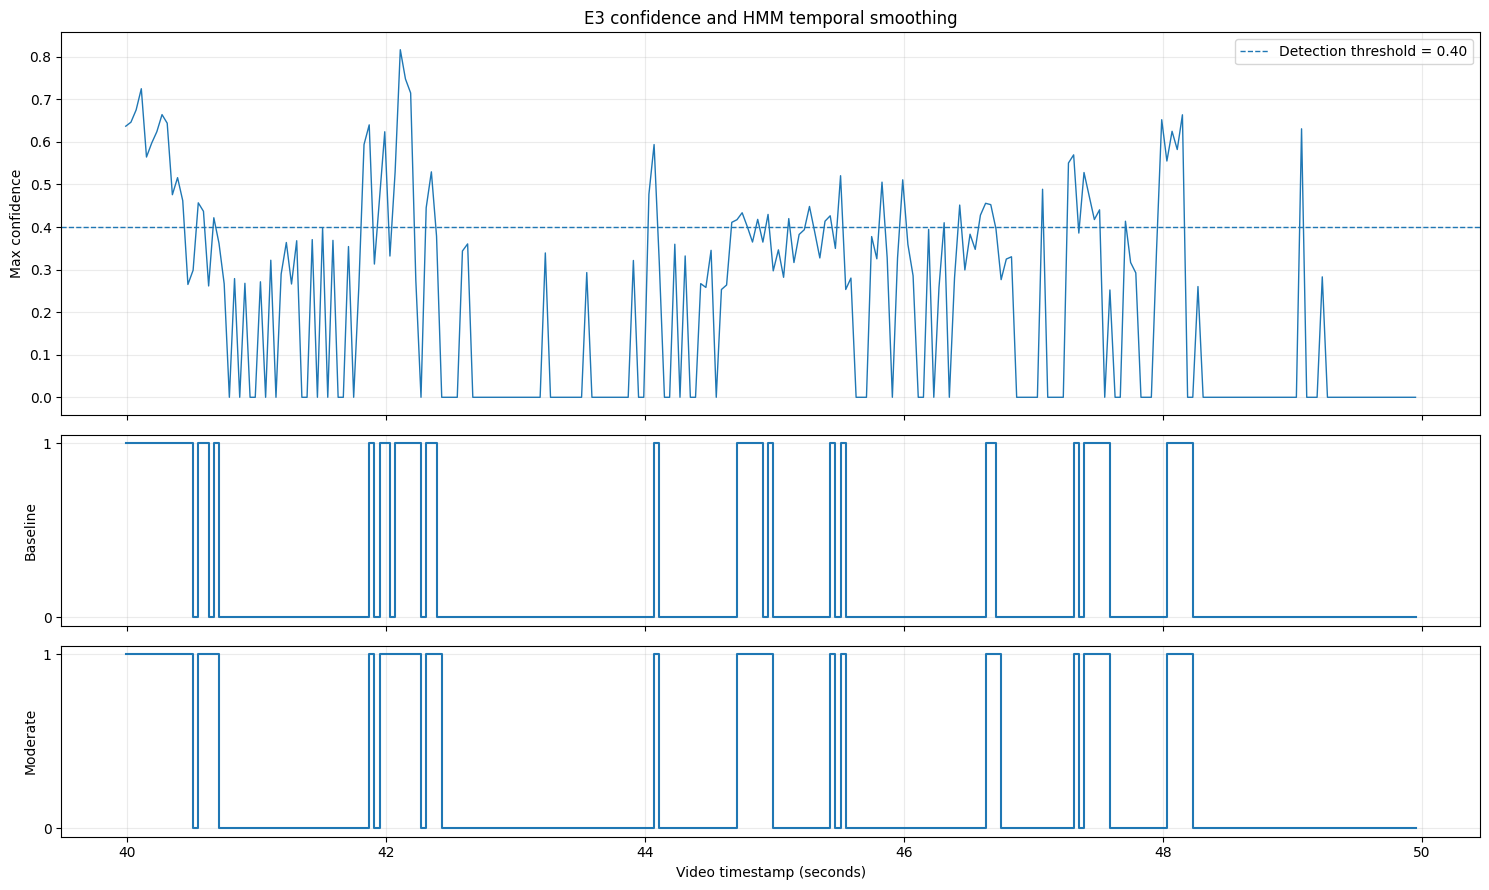

In [ ]:
import matplotlib.pyplot as plt

df_plot = comparison.sort_values("timestamp_seconds").copy()

fig, axes = plt.subplots(
    3, 1, figsize=(15, 9), sharex=True,
    gridspec_kw={"height_ratios": [2, 1, 1]}
)

# Detector confidence
axes[0].plot(
    df_plot["timestamp_seconds"],
    df_plot["max_confidence"],
    linewidth=1
)
axes[0].axhline(
    0.40, linestyle="--", linewidth=1,
    label="Detection threshold = 0.40"
)
axes[0].set_ylabel("Max confidence")
axes[0].set_title("E3 confidence and HMM temporal smoothing")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Baseline state
axes[1].step(
    df_plot["timestamp_seconds"],
    df_plot["hmm_baseline_040"],
    where="post"
)
axes[1].set_ylabel("Baseline")
axes[1].set_yticks([0, 1])
axes[1].grid(alpha=0.25)

# Moderate persistence state
axes[2].step(
    df_plot["timestamp_seconds"],
    df_plot["hmm_moderate_040"],
    where="post"
)
axes[2].set_ylabel("Moderate")
axes[2].set_yticks([0, 1])
axes[2].set_xlabel("Video timestamp (seconds)")
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()

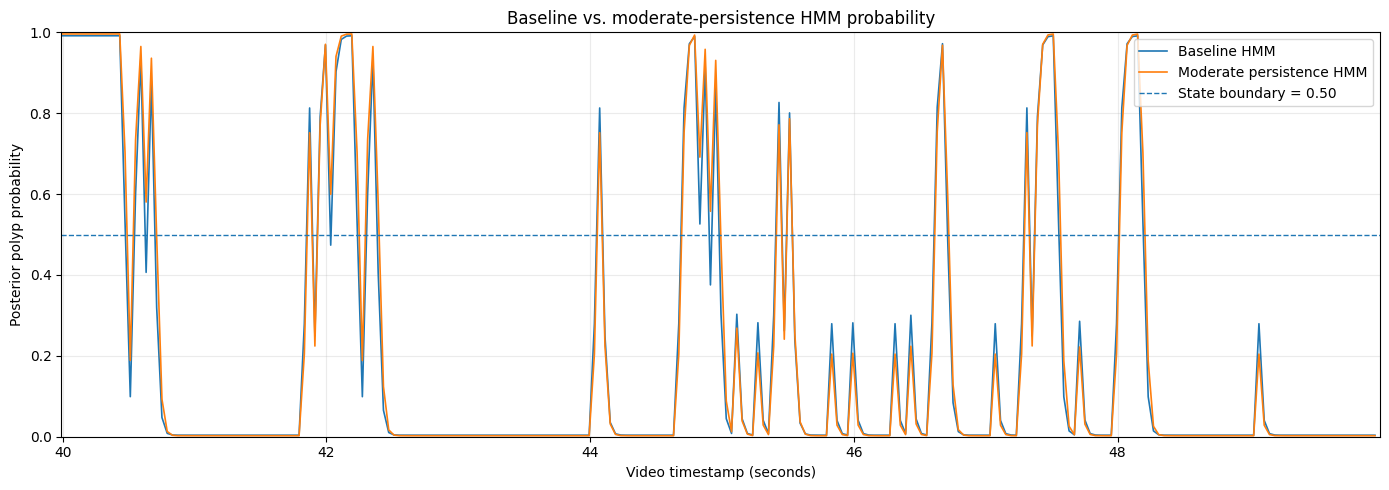

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Re-run HMM configurations to get the continuous posterior probabilities
def get_hmm_probabilities(data, threshold, cfg):
    p0, p1 = 0.95, 0.05
    probabilities = []
    for row in data.itertuples(index=False):
        confidence = float(row.max_confidence)
        has_box = int(row.num_detections) > 0
        detected = has_box and confidence >= threshold

        pred0 = p0 * (1 - cfg["p01"]) + p1 * cfg["p10"]
        pred1 = p0 * cfg["p01"] + p1 * (1 - cfg["p10"])

        if detected:
            l0, l1 = cfg["p_detect_0"], cfg["p_detect_1"]
        else:
            l0 = 1 - cfg["p_detect_0"]
            l1 = 1 - cfg["p_detect_1"]

        w0, w1 = pred0 * l0, pred1 * l1
        total = w0 + w1
        p0, p1 = w0 / total, w1 / total
        probabilities.append(p1)
    return np.array(probabilities)

configs = {
    "baseline": {
        "p01": 0.03, "p10": 0.08,
        "p_detect_0": 0.08, "p_detect_1": 0.90
    },
    "moderate": {
        "p01": 0.02, "p10": 0.04,
        "p_detect_0": 0.08, "p_detect_1": 0.90
    }
}

# Compute full-video probabilities and slice to 39.99–49.99s interval
probs_baseline = get_hmm_probabilities(df, 0.40, configs["baseline"])
probs_moderate = get_hmm_probabilities(df, 0.40, configs["moderate"])

full_df = df.copy()
full_df["baseline_prob"] = probs_baseline
full_df["moderate_prob"] = probs_moderate

# Filter to interval
interval_df = full_df[full_df["timestamp_seconds"].between(39.99, 49.99)].copy()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    interval_df["timestamp_seconds"],
    interval_df["baseline_prob"],
    label="Baseline HMM",
    linewidth=1.2
)

ax.plot(
    interval_df["timestamp_seconds"],
    interval_df["moderate_prob"],
    label="Moderate persistence HMM",
    linewidth=1.2
)

ax.axhline(0.5, linestyle="--", linewidth=1, label="State boundary = 0.50")
ax.set_xlim(39.99, 49.99)
ax.set_ylim(0, 1)
ax.set_xlabel("Video timestamp (seconds)")
ax.set_ylabel("Posterior polyp probability")
ax.set_title("Baseline vs. moderate-persistence HMM probability")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

df = comparison.sort_values("timestamp_seconds").copy()

confidence = df["max_confidence"].to_numpy()
baseline = df["hmm_baseline_040"].to_numpy(dtype=int)
moderate = df["hmm_moderate_040"].to_numpy(dtype=int)

def summarize_states(name, states):
    changes = int(np.sum(states[1:] != states[:-1]))
    positive_frames = int(states.sum())

    print(f"\n{name}")
    print(f"Positive frames: {positive_frames}/{len(states)}")
    print(f"Positive percentage: {100 * positive_frames / len(states):.2f}%")
    print(f"State changes: {changes}")

summarize_states("Baseline HMM", baseline)
summarize_states("Moderate persistence HMM", moderate)

print("\nConfidence distribution:")
print("Minimum:", round(float(confidence.min()), 4))
print("Median:", round(float(np.median(confidence)), 4))
print("90th percentile:", round(float(np.percentile(confidence, 90)), 4))
print("Maximum:", round(float(confidence.max()), 4))


Baseline HMM
Positive frames: 48/250
Positive percentage: 19.20%
State changes: 31

Moderate persistence HMM
Positive frames: 53/250
Positive percentage: 21.20%
State changes: 25

Confidence distribution:
Minimum: 0.0
Median: 0.2591
90th percentile: 0.5293
Maximum: 0.8165


Baseline HMM: positive_frames=48/250, positive_percent=19.20%, state_changes=31
Moderate HMM: positive_frames=53/250, positive_percent=21.20%, state_changes=25
E5 confidence-aware HMM: positive_frames=27/250, positive_percent=10.80%, state_changes=6

First 30 frames:


,frame,timestamp_seconds,max_confidence,hmm_baseline_040,hmm_moderate_040,e5_confidence_state,e5_polyp_probability
0,1000,39.9935,0.6368,1,1,0,0.1563
1,1001,40.0335,0.6463,1,1,0,0.3491
2,1002,40.0735,0.6750,1,1,1,0.6161
3,1003,40.1135,0.7249,1,1,1,0.8457
4,1004,40.1535,0.5644,1,1,1,0.8947
5,1005,40.1935,0.5970,1,1,1,0.9316
6,1006,40.2335,0.6240,1,1,1,0.9546
7,1007,40.2735,0.6640,1,1,1,0.9696
8,1008,40.3134,0.6440,1,1,1,0.9730
9,1009,40.3534,0.4759,1,1,1,0.9509


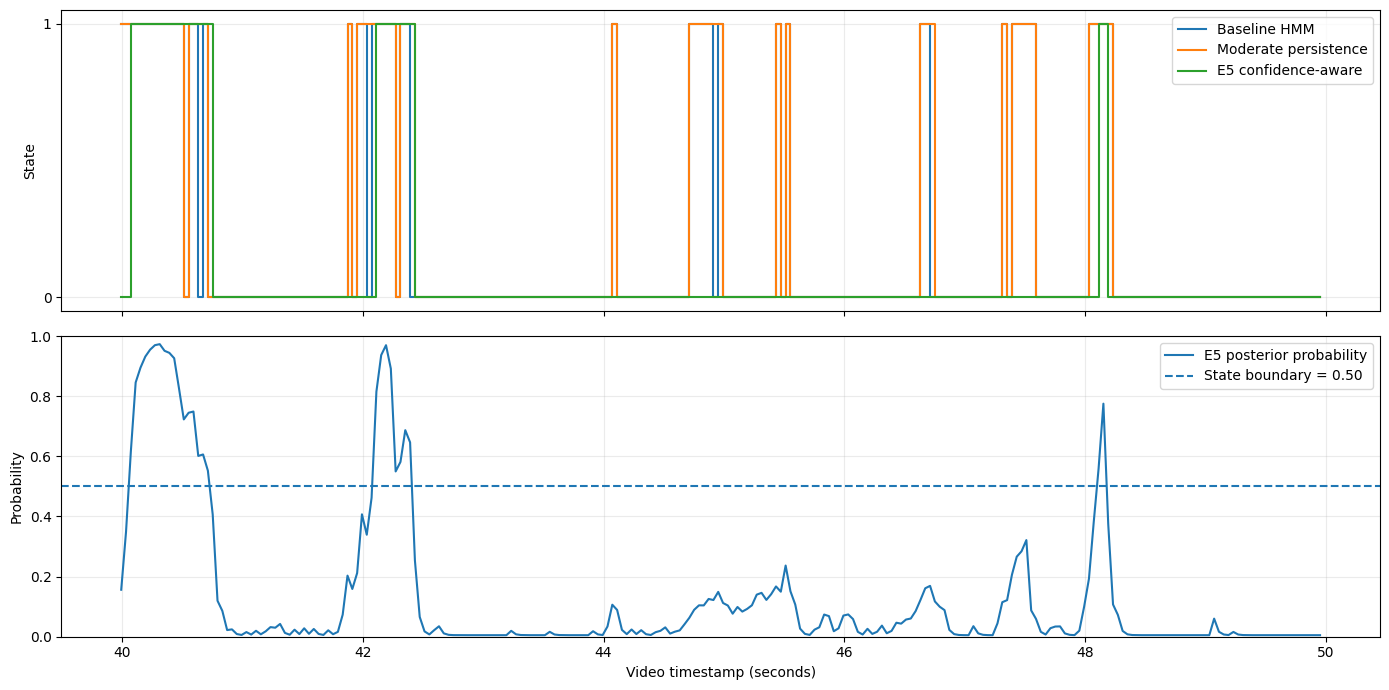

In [ ]:

import numpy as np
import pandas as pd

# Uses the existing comparison DataFrame for the 40–50 s interval.
df = comparison.sort_values("timestamp_seconds").reset_index(drop=True).copy()

THRESHOLD = 0.40
P01 = 0.02  # no-polyp -> polyp
P10 = 0.04  # polyp -> no-polyp
INITIAL_POLYP = 0.05
BETA = 4.0  # experimental observation strength

def run_confidence_hmm(confidences):
    p1 = INITIAL_POLYP
    probabilities = []
    states = []

    for confidence in confidences:
        confidence = float(np.clip(confidence, 0.0, 1.0))

        # Predict state probabilities using moderate persistence.
        predicted_1 = (1 - p1) * P01 + p1 * (1 - P10)
        predicted_0 = 1 - predicted_1

        # Experimental likelihood ratio:
        # confidence above threshold supports polyp;
        # confidence below threshold supports no-polyp.
        log_lr = BETA * (confidence - THRESHOLD)
        lr = np.exp(np.clip(log_lr, -10, 10))

        # Bayes update using the likelihood ratio.
        prior_odds = predicted_1 / max(predicted_0, 1e-12)
        posterior_odds = prior_odds * lr
        p1 = posterior_odds / (1 + posterior_odds)

        probabilities.append(p1)
        states.append(int(p1 >= 0.5))

    return np.array(states), np.array(probabilities)

confidences = df["max_confidence"].fillna(0).to_numpy()

df["e5_confidence_state"], df["e5_polyp_probability"] = (
    run_confidence_hmm(confidences)
)

def state_summary(name, states):
    changes = int(np.sum(states[1:] != states[:-1]))
    positives = int(np.sum(states))
    print(
        f"{name}: positive_frames={positives}/"
        f"{len(states)}, positive_percent="
        f"{100 * positives / len(states):.2f}%, "
        f"state_changes={changes}"
    )

state_summary("Baseline HMM", df["hmm_baseline_040"].to_numpy())
state_summary("Moderate HMM", df["hmm_moderate_040"].to_numpy())
state_summary("E5 confidence-aware HMM", df["e5_confidence_state"].to_numpy())

print("\nFirst 30 frames:")
display(df[[
    "frame",
    "timestamp_seconds",
    "max_confidence",
    "hmm_baseline_040",
    "hmm_moderate_040",
    "e5_confidence_state",
    "e5_polyp_probability"
]].head(30).round(4))

# Plot the three binary state sequences and E5 probability.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

t = df["timestamp_seconds"]

axes[0].step(t, df["hmm_baseline_040"], where="post",
             label="Baseline HMM")
axes[0].step(t, df["hmm_moderate_040"], where="post",
             label="Moderate persistence")
axes[0].step(t, df["e5_confidence_state"], where="post",
             label="E5 confidence-aware")
axes[0].set_ylabel("State")
axes[0].set_yticks([0, 1])
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(t, df["e5_polyp_probability"],
             label="E5 posterior probability")
axes[1].axhline(0.5, linestyle="--",
                label="State boundary = 0.50")
axes[1].set_xlabel("Video timestamp (seconds)")
axes[1].set_ylabel("Probability")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


,beta,positive_frames,positive_percent,state_changes,mean_probability
0,2.0,20,8.0,6,0.1262
1,3.0,25,10.0,6,0.1307
2,4.0,27,10.8,6,0.1341
3,5.0,29,11.6,10,0.1368
4,6.0,29,11.6,8,0.1394


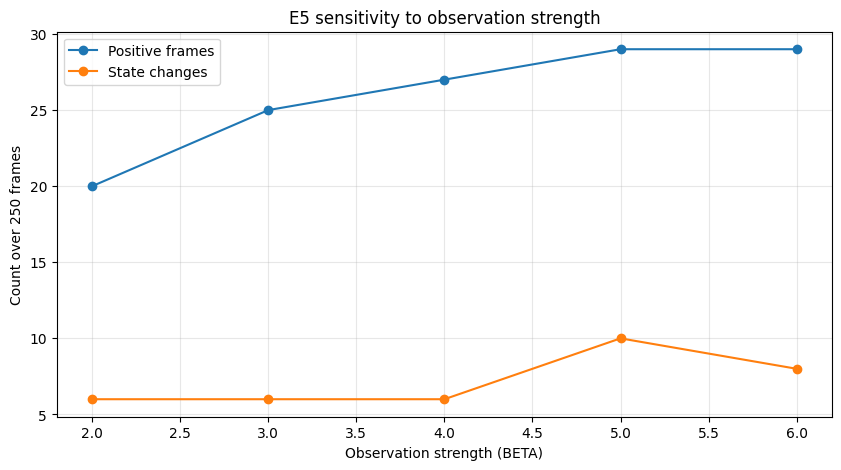

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = comparison.sort_values("timestamp_seconds").reset_index(drop=True)
confidences = df["max_confidence"].fillna(0).to_numpy()

def run_e5(confidences, beta, threshold=0.40,
           p01=0.02, p10=0.04, initial=0.05):
    p1 = initial
    states, probabilities = [], []

    for confidence in confidences:
        predicted_1 = (1 - p1) * p01 + p1 * (1 - p10)
        predicted_0 = 1 - predicted_1

        log_lr = beta * (float(confidence) - threshold)
        lr = np.exp(np.clip(log_lr, -10, 10))

        odds = (predicted_1 / max(predicted_0, 1e-12)) * lr
        p1 = odds / (1 + odds)

        probabilities.append(p1)
        states.append(int(p1 >= 0.5))

    return np.array(states), np.array(probabilities)

results = []

for beta in [2.0, 3.0, 4.0, 5.0, 6.0]:
    states, probabilities = run_e5(confidences, beta)
    results.append({
        "beta": beta,
        "positive_frames": int(states.sum()),
        "positive_percent": round(100 * states.mean(), 2),
        "state_changes": int(np.sum(states[1:] != states[:-1])),
        "mean_probability": round(float(probabilities.mean()), 4)
    })

results_df = pd.DataFrame(results)
display(results_df)

plt.figure(figsize=(10, 5))
plt.plot(results_df["beta"], results_df["positive_frames"],
         marker="o", label="Positive frames")
plt.plot(results_df["beta"], results_df["state_changes"],
         marker="o", label="State changes")
plt.xlabel("Observation strength (BETA)")
plt.ylabel("Count over 250 frames")
plt.title("E5 sensitivity to observation strength")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [ ]:

import pandas as pd
import numpy as np

# Reuse the existing 40–50 second comparison DataFrame.
df = comparison.sort_values("timestamp_seconds").reset_index(drop=True).copy()

e5_states, e5_probs = run_e5(
    df["max_confidence"].fillna(0).to_numpy(),
    beta=4.0
)

df["e5_beta4_state"] = e5_states
df["e5_beta4_probability"] = e5_probs

disagreements = df[
    df["hmm_baseline_040"].astype(int) != df["e5_beta4_state"]
][[
    "frame",
    "timestamp_seconds",
    "max_confidence",
    "num_detections",
    "hmm_baseline_040",
    "e5_beta4_state",
    "e5_beta4_probability"
]].copy()

print("Baseline vs E5 disagreements:", len(disagreements))
display(disagreements.round(4))

# Save the comparison table to Drive if the folder exists.
from pathlib import Path

out_dir = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM"
)
out_dir.mkdir(parents=True, exist_ok=True)

out_path = out_dir / "E5_beta4_baseline_disagreements.csv"
disagreements.to_csv(out_path, index=False)

print("\nSaved to:", out_path)


Baseline vs E5 disagreements: 31


,frame,timestamp_seconds,max_confidence,num_detections,hmm_baseline_040,e5_beta4_state,e5_beta4_probability
0,1000,39.9935,0.6368,1,1,0,0.1563
1,1001,40.0335,0.6463,1,1,0,0.3491
13,1013,40.5134,0.2984,1,0,1,0.7227
16,1016,40.6334,0.2615,1,0,1,0.6013
18,1018,40.7134,0.3617,1,0,1,0.5522
47,1047,41.8732,0.6400,1,1,0,0.2032
49,1049,41.9532,0.4690,1,1,0,0.2117
50,1050,41.9932,0.6238,1,1,0,0.4070
52,1052,42.0732,0.5292,1,1,0,0.4621
57,1057,42.2731,0.0000,0,0,1,0.5497



Saved to: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/E5_beta4_baseline_disagreements.csv


In [ ]:

import cv2
import math
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display

video_path = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/E4_Final_HMM/Videos/"
    "df1aa095-0cab-4433-97fe-00d456f33615.avi"
)

# Representative disagreements, covering different behaviors.
selected_frames = [
    1013, 1016, 1047, 1050, 1057,
    1060, 1102, 1118, 1122, 1166,
    1185, 1189, 1201, 1205
]

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {video_path}")

thumb_w, thumb_h = 320, 256
label_h = 48
cols = 2
rows = math.ceil(len(selected_frames) / cols)

sheet = Image.new(
    "RGB",
    (cols * thumb_w, rows * (thumb_h + label_h)),
    "white"
)
draw = ImageDraw.Draw(sheet)

for i, frame_no in enumerate(selected_frames):
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_no)
    ok, frame = cap.read()

    if not ok:
        print("Could not read frame:", frame_no)
        continue

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    img = Image.fromarray(rgb)
    img.thumbnail((thumb_w, thumb_h))

    x = (i % cols) * thumb_w
    y = (i // cols) * (thumb_h + label_h)

    sheet.paste(img, (x, y))

    row = df.loc[df["frame"] == frame_no]
    if not row.empty:
        r = row.iloc[0]
        label = (
            f"Frame {frame_no} | {r['timestamp_seconds']:.2f}s\n"
            f"Conf={r['max_confidence']:.3f} | "
            f"Baseline={int(r['hmm_baseline_040'])} | "
            f"E5={int(r['e5_beta4_state'])}"
        )
        draw.text((x + 4, y + thumb_h + 3), label, fill="black")

cap.release()

out_path = (
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run/E4_Final_HMM/"
    "E5_disagreement_contact_sheet.png"
)
sheet.save(out_path)

print("Saved contact sheet:", out_path)
display(sheet)


In [ ]:

from pathlib import Path

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run"
)

DATASET_DIR = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "Kvasir-SEG.yolov8_split"
)

print("=== Existing model checkpoints ===")
for p in EXPERIMENT_DIR.rglob("best.pt"):
    print(p, f"({p.stat().st_size / (1024**2):.1f} MB)")

print("\n=== Dataset configuration files ===")
for root in [DATASET_DIR, EXPERIMENT_DIR]:
    if root.exists():
        for p in root.rglob("data.yaml"):
            print(p)

print("\n=== Test split ===")
for name in ["test", "testing"]:
    p = DATASET_DIR / name
    if p.exists():
        print(name, "exists:", p)


=== Existing model checkpoints ===
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E3_Sakaguchi_Fractional_DWT/weights/best.pt (6.0 MB)
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E2_Sakaguchi_Fractional/weights/best.pt (6.0 MB)
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E1_Sakaguchi/weights/best.pt (6.0 MB)
/content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E0_baseline/weights/best.pt (6.0 MB)

=== Dataset configuration files ===
/content/drive/MyDrive/Capsule_Perception/Kvasir-SEG.yolov8_split/data.yaml

=== Test split ===
test exists: /content/drive/MyDrive/Capsule_Perception/Kvasir-SEG.yolov8_split/test


In [ ]:
from pathlib import Path
import pandas as pd
import torch
from ultralytics import YOLO

BASE = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run"
)

MODEL_PATH = (
    BASE / "training_runs/E3_Sakaguchi_Fractional_DWT/"
    "weights/best.pt"
)
DATA_YAML = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "Kvasir-SEG.yolov8_split/data.yaml"
)

assert MODEL_PATH.exists(), f"Missing model: {MODEL_PATH}"
assert DATA_YAML.exists(), f"Missing dataset config: {DATA_YAML}"

device = 0 if torch.cuda.is_available() else "cpu"
print("Validation device:", "GPU" if device == 0 else "CPU")
print("Model:", MODEL_PATH)

model = YOLO(str(MODEL_PATH))

results = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=16 if device == 0 else 4,
    device=device,
    plots=True,
    verbose=True,
    project=str(BASE / "final_validation"),
    name="E3_test",
    exist_ok=True
)

# Safely fetch the total number of validation/test images processed
num_seen = 150
if hasattr(results, "speed") and isinstance(results.speed, dict):
    # Many YOLOv8 metrics objects contain a speed dict or dataset definitions
    pass

metrics = {
    "model": "E3",
    "precision": float(results.box.mp),
    "recall": float(results.box.mr),
    "mAP50": float(results.box.map50),
    "mAP50_95": float(results.box.map),
    "test_images": int(num_seen),
}

metrics_df = pd.DataFrame([metrics])
out_csv = BASE / "final_validation/E3_test_metrics.csv"
out_csv.parent.mkdir(parents=True, exist_ok=True)
metrics_df.to_csv(out_csv, index=False)

print("\n=== E3 TEST-SET METRICS ===")
display(metrics_df.round(4))
print("Saved metrics:", out_csv)
print("Validation plots:", BASE / "final_validation/E3_test")

Validation device: GPU
Model: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E3_Sakaguchi_Fractional_DWT/weights/best.pt
Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.3 ms, read: 193.5±73.0 MB/s, size: 365.9 KB)
val: Scanning /content/drive/MyDrive/Capsule_Perception/Kvasir-SEG.yolov8_split/test/labels.cache... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 35.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.5it/s 4.0s
                   all        150        156      0.578      0.391      0.385       0.22
Speed: 4.2ms preprocess, 4.8ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/final_validation/E3_te

,model,precision,recall,mAP50,mAP50_95,test_images
0,E3,0.5775,0.391,0.3851,0.2197,150


Saved metrics: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/final_validation/E3_test_metrics.csv
Validation plots: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/final_validation/E3_test


In [ ]:

from pathlib import Path
import yaml

BASE = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run"
)

DATA_YAML = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "Kvasir-SEG.yolov8_split/data.yaml"
)

E3_RUN = BASE / "training_runs/E3_Sakaguchi_Fractional_DWT"

print("=== DATASET CONFIGURATION ===")
print(DATA_YAML.read_text())

print("\n=== E3 TRAINING FILES ===")
if E3_RUN.exists():
    for p in sorted(E3_RUN.rglob("*")):
        if p.is_file() and (
            p.name in {"args.yaml", "results.csv", "hyp.yaml"}
            or p.suffix.lower() in {".yaml", ".yml"}
        ):
            print(f"\n--- {p} ---")
            try:
                print(p.read_text()[:8000])
            except Exception as e:
                print("Could not read:", e)
else:
    print("E3 run directory not found.")


=== DATASET CONFIGURATION ===
train: train/images
val: valid/images
test: test/images

nc: 1
names: ['Polyp']


=== E3 TRAINING FILES ===

--- /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs/E3_Sakaguchi_Fractional_DWT/args.yaml ---
task: detect
mode: train
model: yolov8n.pt
data: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/configs/E3_Sakaguchi_Fractional_DWT_data.yaml
epochs: 50
time: null
patience: 20
batch: 16
imgsz: 640
save: true
save_period: -1
cache: false
device: '0'
workers: 2
project: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/training_runs
name: E3_Sakaguchi_Fractional_DWT
exist_ok: false
pretrained: true
cls_remap: true
optimizer: auto
verbose: true
seed: 42
deterministic: true
single_cls: false
rect: false
cos_lr: false
close_mosaic: 10
resume: false
amp: true
fraction: 1.0
profile: false
freeze: null
multi_scale: 0.0
compile: false
channels_last: null
overlap_mask: true
ma

In [ ]:

from pathlib import Path
import yaml

config_path = Path(
    "/content/drive/MyDrive/Capsule_Perception/"
    "experiments/Professor_Fresh_Run/"
    "configs/E3_Sakaguchi_Fractional_DWT_data.yaml"
)

print("Config exists:", config_path.exists())

if config_path.exists():
    print(config_path.read_text())
    cfg = yaml.safe_load(config_path.read_text())

    print("\nResolved dataset paths:")
    for key in ["train", "val", "test"]:
        value = cfg.get(key)
        if value:
            p = Path(value)
            print(key, "=>", p, "| exists:", p.exists())


Config exists: True
path: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E3_Sakaguchi_Fractional_DWT
train: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E3_Sakaguchi_Fractional_DWT/train/images
val: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E3_Sakaguchi_Fractional_DWT/valid/images
test: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E3_Sakaguchi_Fractional_DWT/test/images
nc: 1
names:
- Polyp


Resolved dataset paths:
train => /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E3_Sakaguchi_Fractional_DWT/train/images | exists: True
val => /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E3_Sakaguchi_Fractional_DWT/valid/images | exists: True
test => /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E3_Sakaguchi_Fractional_DWT/test/images | 

In [ ]:
from pathlib import Path
import pandas as pd
import torch
from ultralytics import YOLO

BASE = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run"
)

MODEL_PATH = (
    BASE / "training_runs/E3_Sakaguchi_Fractional_DWT/"
    "weights/best.pt"
)

DATA_YAML = (
    BASE / "configs/E3_Sakaguchi_Fractional_DWT_data.yaml"
)

device = 0 if torch.cuda.is_available() else "cpu"

model = YOLO(str(MODEL_PATH))

results = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=16 if device == 0 else 4,
    device=device,
    plots=True,
    project=str(BASE / "final_validation"),
    name="E3_enhanced_test",
    exist_ok=True
)

metrics = pd.DataFrame([{
    "model": "E3",
    "dataset": "E3 enhanced test split",
    "precision": float(results.box.mp),
    "recall": float(results.box.mr),
    "mAP50": float(results.box.map50),
    "mAP50_95": float(results.box.map),
    "test_images": 150
}])

out = BASE / "final_validation/E3_enhanced_test_metrics.csv"
metrics.to_csv(out, index=False)

display(metrics.round(4))
print("Saved:", out)


Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 5.5±11.0 ms, read: 137.1±82.6 MB/s, size: 327.2 KB)
val: Scanning /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/datasets/E3_Sakaguchi_Fractional_DWT/test/labels.cache... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 30.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.4it/s 4.1s
                   all        150        156      0.905      0.914      0.936      0.723
Speed: 6.1ms preprocess, 5.3ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/final_validation/E3_enhanced_test


,model,dataset,precision,recall,mAP50,mAP50_95,test_images
0,E3,E3 enhanced test split,0.9048,0.9141,0.9356,0.7226,150


Saved: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/final_validation/E3_enhanced_test_metrics.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run"
)

out_dir = BASE / "final_validation"
out_dir.mkdir(parents=True, exist_ok=True)

metrics = pd.DataFrame([{
    "model": "E3",
    "dataset": "E3 enhanced test split",
    "precision": float(results.box.mp),
    "recall": float(results.box.mr),
    "mAP50": float(results.box.map50),
    "mAP50_95": float(results.box.map),
    "test_images": 150,
    "ground_truth_instances": 156
}])

out = out_dir / "E3_enhanced_test_metrics.csv"
metrics.to_csv(out, index=False)

display(metrics.round(4))
print("Saved successfully:", out)


,model,dataset,precision,recall,mAP50,mAP50_95,test_images,ground_truth_instances
0,E3,E3 enhanced test split,0.9048,0.9141,0.9356,0.7226,150,156


Saved successfully: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/final_validation/E3_enhanced_test_metrics.csv


In [ ]:
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run"
)

checks = {
    "E0 best.pt": BASE / "training_runs/E0_baseline/weights/best.pt",
    "E1 best.pt": BASE / "training_runs/E1_Sakaguchi/weights/best.pt",
    "E2 best.pt": BASE / "training_runs/E2_Sakaguchi_Fractional/weights/best.pt",
    "E3 best.pt": BASE / "training_runs/E3_Sakaguchi_Fractional_DWT/weights/best.pt",
    "E3 validation CSV": BASE / "final_validation/E3_enhanced_test_metrics.csv",
    "E4 HMM folder": BASE / "E4_Final_HMM",
}

print("FINAL OUTPUT VERIFICATION\n")

for name, path in checks.items():
    exists = path.exists()
    print(f"{'OK' if exists else 'MISSING'} | {name}")
    if exists and path.is_file():
        print(f"       Size: {path.stat().st_size / 1024:.1f} KB")

print("\nVerification complete.")

FINAL OUTPUT VERIFICATION

OK | E0 best.pt
       Size: 6104.3 KB
OK | E1 best.pt
       Size: 6104.3 KB
OK | E2 best.pt
       Size: 6104.4 KB
OK | E3 best.pt
       Size: 6104.4 KB
OK | E3 validation CSV
       Size: 0.2 KB
OK | E4 HMM folder

Verification complete.


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Capsule_Perception/experiments/"
    "Professor_Fresh_Run"
)
output_dir = BASE / "final_validation"
output_dir.mkdir(parents=True, exist_ok=True)

comparison_path = BASE / "model_comparison.csv"
if not comparison_path.exists():
    raise FileNotFoundError(
        f"Fresh-run comparison file is missing: {comparison_path}. "
        "Run the E0-E3 training/evaluation cells successfully first."
    )

comparison = pd.read_csv(comparison_path)
required = {"experiment", "precision", "recall", "mAP50", "mAP50_95"}
missing = required - set(comparison.columns)
if missing:
    raise ValueError(f"Comparison CSV is missing columns: {sorted(missing)}")

summary = comparison.rename(columns={
    "experiment": "Model",
    "precision": "Precision",
    "recall": "Recall",
    "mAP50": "mAP50",
    "mAP50_95": "mAP50_95",
}).copy()

summary["Model"] = summary["Model"].replace({
    "E0_baseline": "E0",
    "E1_Sakaguchi": "E1",
    "E2_Sakaguchi_Fractional": "E2",
    "E3_Sakaguchi_Fractional_DWT": "E3",
})

out = output_dir / "E0_E1_E2_E3_fresh_run_summary.csv"
summary.to_csv(out, index=False)
display(summary.round(4))
print("Saved fresh-run summary:", out)


,Model,Precision,Recall,mAP50,mAP50_95,best_weights,data_yaml,test_images,test_labels
0,E0,0.8949,0.9359,0.9376,0.7417,/content/drive/MyDrive/Capsule_Perception/expe...,/content/drive/MyDrive/Capsule_Perception/expe...,150,150
1,E1,0.8989,0.8549,0.9218,0.7191,/content/drive/MyDrive/Capsule_Perception/expe...,/content/drive/MyDrive/Capsule_Perception/expe...,150,150
2,E2,0.8952,0.8397,0.9110,0.7197,/content/drive/MyDrive/Capsule_Perception/expe...,/content/drive/MyDrive/Capsule_Perception/expe...,150,150
3,E3,0.9048,0.9141,0.9356,0.7226,/content/drive/MyDrive/Capsule_Perception/expe...,/content/drive/MyDrive/Capsule_Perception/expe...,150,150


Saved fresh-run summary: /content/drive/MyDrive/Capsule_Perception/experiments/Professor_Fresh_Run/final_validation/E0_E1_E2_E3_fresh_run_summary.csv
